# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 15: Explainability

### Objective

The earlier notebooks measured **how well** the models work. This notebook asks **why**: what the recognizers look at, how their embeddings are organised, and whether the synthetic images really keep the identity of the person they were generated for.

```text
Attention regions     Grad-CAM (CNN / Swin) and Attention Rollout (ViT): which parts of the iris strip drive a decision
Embedding clusters    t-SNE and UMAP: how real, held-out, synthetic, and unseen images group by identity
Identity preservation numbers that say whether synthetic images stay in their identity's cluster, and how much variation they add
```

The notebook must:

1. Compute **Grad-CAM** and **Attention Rollout** maps for the Notebook 07 baselines and the Notebook 13 final model, on real and synthetic images.
2. Summarise the attention statistically: **where along the iris** (from the pupil edge to the limbus, and around the iris) and **how much on valid iris texture** instead of eyelid, eyelash, and reflection areas.
3. Project the embeddings with **t-SNE** and **UMAP**, with real, held-out, synthetic, and unseen-person images in one picture.
4. Measure **identity preservation** and **intra-class variation** of the synthetic images, using models that never saw them.
5. Save the figures and tables.

### Important boundary of this notebook

This notebook performs **explanation only**.

It trains nothing, tunes nothing, and writes no images into any dataset. Explanations are **descriptive evidence**, not proof: they show what a model does, not that this is why it is accurate.

## 1. Research rationale

### 1.1 What each method shows

| Method | What it produces | How to read it |
|---|---|---|
| **Grad-CAM** | A heat map over the strip: how much each region increased the similarity between this image and its identity prototype | Bright = the region pushed the embedding towards the person's prototype |
| **Attention Rollout** (ViT only) | A heat map from the attention of the class token, accumulated through all layers | Bright = the region the transformer attended to |
| **t-SNE / UMAP** | A 2-D map in which images with similar embeddings are close | One cluster per person is good; distances **between** clusters carry little meaning |
| **Identity-preservation numbers** | Rank-1, similarity, spread, and separation of real versus synthetic images | See section 1.4 |

### 1.2 Grad-CAM for an embedding model

The recognizers output a 256-d embedding, not class scores. The quantity explained is therefore the **cosine similarity `s` between the embedding of the image and the identity prototype** (the normalised mean embedding of the person's real support images). For a chosen convolutional layer with feature maps `A_k`:

```text
weight_k = mean over positions of ds/dA_k          CAM = ReLU( sum_k weight_k * A_k )
```

and the map is upsampled to the 64 x 512 strip. It answers: *which parts of this image made it look like this person?* Layers at stride 16 are used (4 x 32 maps) because the final layer (2 x 16) is too coarse for a strip this small.

### 1.3 Attention Rollout, and what the maps are averaged into

For a Vision Transformer the attention of every layer is averaged over the heads, mixed with the identity (the residual connection), renormalised, and multiplied through the layers; the row of the class token gives one weight per image patch. Swin has windowed attention, for which rollout is not defined, so Swin uses Grad-CAM.

To compare models, the maps are summarised, over many images, into:

| Statistic | Meaning |
|---|---|
| **Radial profile** | Share of attention per row, from the **pupil edge (row 0) to the limbus (row 63)** |
| **Angular profile** | Share of attention around the iris (32 bins) |
| **Entropy** | 1 = spread evenly over the strip, 0 = a single spot |
| **Inner share** | Share of attention on the half of the iris nearer the pupil |
| **Valid-texture ratio** | Attention on **valid iris pixels** (from the Notebook 03 noise masks) divided by the share of valid pixels: above 1 means the model looks at usable texture more than chance, below 1 means it looks at eyelid / eyelash / reflection areas |

The proposal asks for "saliency overlap with crypt and furrow regions". No crypt or furrow annotations exist for these datasets, so the **valid-texture ratio is used as a documented proxy**. The proposal's "structural consistency score" and expert ratings are not implemented.

### 1.4 Identity preservation and intra-class variation

For the training identities, using prototypes built from the **real support images only**:

| Number | Meaning | Good looks like |
|---|---|---|
| `syn_rank1_own` | Share of synthetic images whose nearest identity is the one they were made for | Far above `chance_rank1`, close to the real held-out value |
| `real_query_rank1_*` | The same for real held-out images (the reference), with prototypes from real images only and from real + synthetic | Adding synthetic images should not lower it |
| `real_query_1nn_*` | Image-level nearest-neighbour version: is a held-out real image closest to an image of its own person? | Higher with the synthetic images added means they cover real variation |
| `syn_sim_own` / `real_query_sim_own` | Mean cosine similarity to the own prototype | Synthetic close to real |
| `diversity_ratio_embedding` | Variation among synthetic images of one person divided by the variation among real images | Around 1 (much below 1 = collapse) |
| `separation_*` | Distance between identities divided by variation within identities | High, and not lower with the synthetic images added |

### 1.5 Which models are the judges

| Model | Trained on synthetic images? | Use |
|---|---|---|
| Notebook 07 `real_only`, `real_traditional_aug`, same-code control | **No** | **Independent judges** of the synthetic images: they never saw them |
| Notebook 13 final model | **Yes** | Attention maps and cluster pictures are informative; its identity numbers on the synthetic images are **circular** (marked `trained_on_synthetic` and left out of the sanity checks) |

### 1.6 Leakage rules and limits

- Nothing is trained or selected here. Synthetic images are those of **training identities**; the notebook asserts this. "Unseen people" are **validation** identities; test identities are not used.
- **Attention is not causal proof.** Grad-CAM and rollout show what a model attends to; they can look plausible for a wrong reason.
- **t-SNE and UMAP distort distances.** Read clusters, not distances between clusters, and not cluster sizes. The notebook reports how well each map preserves local neighbourhoods (neighbour recall).
- **Run `QUICK_TEST = True` first.** **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first; t-SNE is implemented in PyTorch.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import hashlib
import importlib.util
import json
import math
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
except ImportError as error:
    raise ImportError(
        "Notebook 15 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

- `QUICK_TEST = True` explains the quick-test models of Notebooks 07 and 13 with tiny sample sizes and writes to a separate folder.
- `SHOTS_TO_RUN`: the shot counts to explain (one by default, to keep the figures readable). `BACKBONE` and `SEED` choose the checkpoints; `MODEL_SPECS` lists the model kinds to compare (a kind whose checkpoint does not exist is skipped with a note).
- `SYNTHETIC_SOURCE`: `"accepted"` (Notebook 11) or `"all"` (Notebook 10).
- `ANALYSIS_IDENTITIES`, `SYNTHETIC_PER_IDENTITY_ANALYSIS`, `UNSEEN_IDENTITIES`: how many training identities, synthetic images per identity, and unseen (validation) identities go into the analysis.
- `GRADCAM_LAYERS`: the layer whose feature maps Grad-CAM uses, per backbone (stride 16 by default).
- `PROJECTION_METHODS`: `"tsne"`, `"umap"` (needs `pip install umap-learn`; PCA replaces it if missing). `TSNE_*`, `UMAP_*`: their settings.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = explain the quick-test models with tiny samples, separate folder

# ---- what to explain ----
SHOTS_TO_RUN = [3]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]
BACKBONE = "efficientnet_b0"
SEED = 42
MODEL_SPECS = [
    {"name": "Notebook 07: real only", "key": "baseline_real_only", "family": "baseline",
     "data_variant": "real_only", "loss_variant": "arcface"},
    {"name": "Notebook 07: traditional augmentation", "key": "baseline_traditional_aug", "family": "baseline",
     "data_variant": "real_traditional_aug", "loss_variant": "arcface"},
    {"name": "Same-code control: real only", "key": "control_real_only", "family": "final",
     "data_variant": "real_only", "loss_variant": "arcface_triplet_center"},
    {"name": "Final: real + synthetic", "key": "final_real_plus_synthetic", "family": "final",
     "data_variant": "real_plus_synthetic", "loss_variant": "arcface_triplet_center"},
]

# ---- synthetic images (Notebooks 10 and 11) ----
SYNTHETIC_SOURCE = "accepted"       # "accepted" (Notebook 11) or "all" (Notebook 10, unfiltered)
GENERATOR_SEED = 42                 # the Notebook 09 / 10 run: diffusion__<K>shot__seed<GENERATOR_SEED>
UPSTREAM_FROM_QUICKTEST = QUICK_TEST

INPUT_HW = (64, 512)                # normalized iris strips
KNOWN_BACKBONES = {                 # name -> (feature size, needs a square input)
    "resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_b3": (1536, False),
    "efficientnet_v2_s": (1280, False), "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True),
}

# ---- analysis sets ----
ANALYSIS_IDENTITIES = 200           # training identities in the identity-preservation analysis
SYNTHETIC_PER_IDENTITY_ANALYSIS = 10
UNSEEN_IDENTITIES = 50              # validation identities used as "unseen people"
ANALYSIS_SEED = 2025
EMBED_BATCH_SIZE = 128

# ---- attention (Grad-CAM / Attention Rollout) ----
CAM_IMAGES_PER_GROUP = 200          # images per group (real held-out, synthetic, unseen real) for the statistics
CAM_BATCH_SIZE = 16
ANGULAR_BINS = 32
GRADCAM_LAYERS = {                  # stride-16 layers (4 x 32 maps); ViT uses Attention Rollout instead
    "resnet50": "backbone.layer3", "efficientnet_b0": "backbone.features.5", "efficientnet_b3": "backbone.features.5",
    "efficientnet_v2_s": "backbone.features.5", "convnext_tiny": "backbone.features.5", "swin_t": "backbone.features.5",
}
CHANNELS_LAST_BACKBONES = {"swin_t"}    # their feature maps are [B, H, W, C]
FIGURE_IDENTITIES = 3               # training identities shown in the attention figure

# ---- embedding projections ----
PROJECTION_METHODS = ["tsne", "umap"]
PROJECTION_IDENTITIES = 8           # training identities in the cluster pictures
UNSEEN_PROJECTION_IDENTITIES = 4
TSNE_PERPLEXITY = 30.0
TSNE_ITERATIONS = 750
UMAP_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
NEIGHBOR_RECALL_K = 10

if QUICK_TEST:
    SHOTS_TO_RUN = [1]
    BACKBONE = "resnet50"           # the backbone Notebook 07's and 13's quick tests train
    ANALYSIS_IDENTITIES = 8
    SYNTHETIC_PER_IDENTITY_ANALYSIS = 4
    UNSEEN_IDENTITIES = 4
    CAM_IMAGES_PER_GROUP = 8
    FIGURE_IDENTITIES = 2
    PROJECTION_IDENTITIES = 4
    UNSEEN_PROJECTION_IDENTITIES = 2
    TSNE_ITERATIONS = 250
    print("QUICK_TEST is ON: quick-test models, tiny samples, separate output folder.")

# ---- sanity checks on the configuration itself ----
assert BACKBONE in KNOWN_BACKBONES, f"Unknown backbone '{BACKBONE}'. Choose from {sorted(KNOWN_BACKBONES)}"
assert BACKBONE.startswith("vit") or BACKBONE in GRADCAM_LAYERS, f"No Grad-CAM layer is configured for '{BACKBONE}'"
assert SYNTHETIC_SOURCE in {"accepted", "all"}, "SYNTHETIC_SOURCE must be 'accepted' or 'all'"
assert tuple(INPUT_HW) == (64, 512) and INPUT_HW[1] % ANGULAR_BINS == 0, "INPUT_HW must be 64 x 512 and divisible into ANGULAR_BINS"
assert set(PROJECTION_METHODS) <= {"tsne", "umap", "pca"}, "PROJECTION_METHODS must be a subset of tsne / umap / pca"
assert len(SHOTS_TO_RUN) >= 1 and len(MODEL_SPECS) >= 1 and ANALYSIS_IDENTITIES >= 2
assert len({spec["key"] for spec in MODEL_SPECS}) == len(MODEL_SPECS), "model keys must be unique"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

UMAP_AVAILABLE = importlib.util.find_spec("umap") is not None
active_methods = [m for m in PROJECTION_METHODS if m != "umap" or UMAP_AVAILABLE]
if "umap" in PROJECTION_METHODS and not UMAP_AVAILABLE:
    print("NOTE: 'umap-learn' is not installed (`pip install umap-learn`); PCA is used instead of UMAP.")
    active_methods.append("pca")

print("Shots:", SHOTS_TO_RUN, "| backbone:", BACKBONE, "| device:", DEVICE, "| projections:", active_methods)

NOTE: 'umap-learn' is not installed (`pip install umap-learn`); PCA is used instead of UMAP.
Shots: [3] | backbone: efficientnet_b0 | device: cuda | projections: ['tsne', 'pca']


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
SYNTHETIC_DIR = PROJECT_ROOT / f"generated_images{upstream_suffix}"
SYNTHETIC_MANIFEST_PATH = PROJECT_ROOT / "results" / f"synthetic_generation{upstream_suffix}" / "synthetic_manifest.csv"
ACCEPTED_MANIFEST_PATH = PROJECT_ROOT / "results" / f"identity_verification{upstream_suffix}" / "accepted_manifest.csv"
BASELINE_DIR = PROJECT_ROOT / "checkpoints" / f"baseline_recognition{upstream_suffix}"
FINAL_DIR = PROJECT_ROOT / "checkpoints" / f"final_recognition{upstream_suffix}"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"explainability{suffix}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Synthetic images (read):", SYNTHETIC_DIR)
print("Notebook 15 results:", RESULTS_DIR)

Synthetic images (read): E:\Research\LargeScale_Synthetic_Iris_Generation\generated_images
Notebook 15 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability


## 5. Utility functions

Real images are read once and cached. Synthetic images are never resized: a wrong-size file stops the notebook, because Notebook 10 guarantees the size. `verify_id` is built exactly as in Notebooks 11 and 12.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def safe_name(text):
    return str(text).replace("/", "__").replace(" ", "_")


def torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def make_generator_run_id(shot):
    return f"diffusion__{shot}shot__seed{GENERATOR_SEED}"


def ratio(numerator, denominator):
    if not np.isfinite(numerator) or not np.isfinite(denominator) or denominator == 0:
        return float("nan")
    return float(numerator / denominator)


def pick_evenly(items, count):
    '''Up to `count` items spread evenly over the list (deterministic).'''
    items = list(items)
    if len(items) <= count:
        return items
    positions = np.unique(np.linspace(0, len(items) - 1, count).round().astype(int))
    return [items[i] for i in positions]


def deterministic_order(names):
    return sorted(names, key=lambda c: (zlib.crc32(f"{ANALYSIS_SEED}|{c}".encode("utf-8")), c))


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def read_synthetic(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != tuple(INPUT_HW):
        raise ValueError(f"Synthetic image is missing, unreadable, or not {INPUT_HW}: {path}")
    return image


def stack_synthetic(relative_paths):
    return torch.from_numpy(np.stack([read_synthetic(SYNTHETIC_DIR / p) for p in relative_paths]))


def load_valid_masks(noise_mask_paths):
    '''Valid-texture masks (True = usable iris pixel) from the Notebook 03 noise masks.
    Returns (masks [N, H, W] bool, available [N] bool).'''
    masks = torch.ones(len(noise_mask_paths), *INPUT_HW, dtype=torch.bool)
    available = np.zeros(len(noise_mask_paths), dtype=bool)

    for i, path in enumerate(noise_mask_paths):
        if isinstance(path, str) and path and Path(path).exists():
            mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if mask is not None:
                if mask.shape != tuple(INPUT_HW):
                    mask = cv2.resize(mask, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_NEAREST)
                masks[i] = torch.from_numpy(mask == 0)
                available[i] = True

    return masks, available

## 6. Load the datasets and check the upstream outputs

- `fewshot_manifest_long.csv` (Notebook 06): the **real** images and their splits. Its `noise_mask_path` column points to the Notebook 03 noise masks used for the valid-texture statistic (images without a mask are simply left out of that statistic).
- The synthetic manifest (Notebook 11's `accepted_manifest.csv`, or Notebook 10's `synthetic_manifest.csv` when `SYNTHETIC_SOURCE = "all"`): the generated images.

A shot is explained only if it has synthetic images. The leakage guards of Notebooks 11 and 12 are repeated: all synthetic images must be labelled `train`, their identities must be training identities, and none of their people may appear in another split.

In [6]:
# ============================================================
# 6. Load the datasets
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {"shot", "image_id", "dataset", "class_id", "subject_key", "split", "role", "relative_path", "source_path"}
missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

if "noise_mask_path" not in long_manifest.columns:
    long_manifest["noise_mask_path"] = np.nan
    print("NOTE: the manifest has no noise_mask_path column; the valid-texture statistic will be skipped.")

available_datasets = sorted(long_manifest["dataset"].unique())
for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, f"TRAIN_DATASETS contains '{dataset_name}', not in {available_datasets}"

synthetic_path = ACCEPTED_MANIFEST_PATH if SYNTHETIC_SOURCE == "accepted" else SYNTHETIC_MANIFEST_PATH
if not synthetic_path.exists():
    hint = ("11_Identity_Verification.ipynb (or set SYNTHETIC_SOURCE = 'all')" if SYNTHETIC_SOURCE == "accepted"
            else "10_Synthetic_Image_Generation.ipynb (run it to the end)")
    raise FileNotFoundError(f"Missing: {synthetic_path}\nRun {hint} first.")

def add_verify_id(table):
    '''Unique image ID built exactly as in Notebooks 11 and 12 (run, identity, index).'''
    if len(table) == 0:
        table["verify_id"] = pd.Series(dtype=object)
        return table
    table["verify_id"] = (table["generator_run_id"] + "|" + table["class_id"]
                          + "|syn_" + table["synth_index"].astype(int).map("{:03d}".format))
    return table


synthetic_manifest = pd.read_csv(synthetic_path, dtype={"identity": str, "eye": str})
required_synthetic = {"class_id", "subject_key", "shot", "synth_index", "relative_path", "generator_run_id"}
missing = required_synthetic.difference(synthetic_manifest.columns)
if missing:
    raise ValueError(f"The synthetic manifest is missing required columns: {sorted(missing)}")

synthetic_manifest = add_verify_id(synthetic_manifest)

if "split" not in synthetic_manifest.columns:
    # Notebook 11's accepted manifest does not carry the split, so it is taken from Notebook 10's manifest
    if not SYNTHETIC_MANIFEST_PATH.exists():
        raise FileNotFoundError(f"Missing: {SYNTHETIC_MANIFEST_PATH}\nRun 10_Synthetic_Image_Generation.ipynb first.")
    original = add_verify_id(pd.read_csv(SYNTHETIC_MANIFEST_PATH, dtype={"identity": str, "eye": str}))
    split_of = dict(zip(original["verify_id"], original["split"]))
    unknown = [v for v in synthetic_manifest["verify_id"] if v not in split_of]
    assert not unknown, f"{len(unknown)} accepted images are not in Notebook 10's manifest (a different run?)"
    synthetic_manifest["split"] = synthetic_manifest["verify_id"].map(split_of)

assert synthetic_manifest["verify_id"].is_unique, "verify_id is not unique: the synthetic manifest repeats an image"

shots_to_run = []
for shot in SHOTS_TO_RUN:
    rows = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == make_generator_run_id(shot))]
    if len(rows) == 0:
        print(f"WARNING: no synthetic images for {shot}-shot ({make_generator_run_id(shot)}); skipping it.")
        continue

    real = long_manifest[long_manifest["shot"] == shot]
    train_support = real[(real["split"] == "train") & (real["role"] == "support") & (real["dataset"].isin(TRAIN_DATASETS))]
    assert (rows["split"] == "train").all(), f"{shot}-shot: a synthetic image is not labelled as a training image"
    assert set(rows["class_id"]) <= set(train_support["class_id"]), f"{shot}-shot: a synthetic identity is not a training identity"
    held_out = set(real.loc[~real["class_id"].isin(set(train_support["class_id"])), "subject_key"])
    assert not (set(rows["subject_key"]) & held_out), f"{shot}-shot: a synthetic identity shares a person with another split"
    absent = [p for p in rows["relative_path"].head(2000) if not (SYNTHETIC_DIR / p).exists()]
    assert not absent, f"{shot}-shot: {len(absent)} synthetic images are missing from {SYNTHETIC_DIR} (checked a sample)"
    shots_to_run.append(shot)

if not shots_to_run:
    raise RuntimeError("No requested shot has synthetic images, so there is nothing to explain.")

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be explained:", shots_to_run)
display(synthetic_manifest[synthetic_manifest["shot"].isin(shots_to_run)]
        .groupby("shot").agg(identities=("class_id", "nunique"), synthetic_images=("verify_id", "count")).reset_index())

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be explained: [3]


,shot,identities,synthetic_images
0,3,228,338


## 7. The models

`EmbeddingNet` is the class of Notebooks 07, 13 and 14: a backbone followed by a 256-d embedding layer. Its checkpoints from **all** these notebooks have the same layout, so one class loads them all; the weights come from the checkpoint and nothing is downloaded.

For every model kind in `MODEL_SPECS` the checkpoint is looked up by name:

| Family | Folder | File name |
|---|---|---|
| `baseline` (Notebook 07) | `checkpoints/baseline_recognition/` | `<variant>__<backbone>__<K>shot__seed<S>.pt` |
| `final` (Notebook 13) | `checkpoints/final_recognition/` | `<data>__<loss>__<backbone>__<K>shot__seed<S>.pt` |

A model kind whose checkpoint is missing is skipped with a note. Whether a model was trained on synthetic images is read from the checkpoint (`n_synthetic_images`).

In [7]:
# ============================================================
# 7. Model class and loading
# ============================================================

def build_backbone(name):
    '''Backbone without pretrained weights (they come from the checkpoint); classification head replaced by the identity.'''
    builder = getattr(tv_models, name, None)
    if builder is None:
        raise ValueError(f"torchvision has no model named '{name}'. Update torchvision.")

    model = builder(weights=None)

    if name.startswith("resnet"):
        model.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        model.classifier = nn.Identity()
    elif name.startswith("convnext"):
        model.classifier[2] = nn.Identity()
    elif name.startswith("swin"):
        model.head = nn.Identity()
    elif name.startswith("vit"):
        model.heads = nn.Identity()
    else:
        raise ValueError(name)

    return model, KNOWN_BACKBONES[name][0], KNOWN_BACKBONES[name][1]


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, square_size):
        super().__init__()
        self.backbone, feature_dim, self.needs_square = build_backbone(backbone_name)
        self.square_size = square_size
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # x: float [B, 1, H, W] in [0, 1]
        x = x.expand(-1, 3, -1, -1)
        x = (x - self.mean) / self.std
        if self.needs_square:
            x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


def model_path(spec, shot):
    if spec["family"] == "baseline":
        return BASELINE_DIR / f"{spec['data_variant']}__{BACKBONE}__{shot}shot__seed{SEED}.pt"
    return FINAL_DIR / f"{spec['data_variant']}__{spec['loss_variant']}__{BACKBONE}__{shot}shot__seed{SEED}.pt"


def load_model(path, shot):
    '''Load a checkpoint; returns (model in evaluation mode, checkpoint).'''
    checkpoint = torch_load(path)

    for key in ["model_state", "backbone", "embedding_dim", "input_hw", "vit_input_size", "shot"]:
        assert key in checkpoint, f"{Path(path).name}: the checkpoint has no '{key}'"

    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), f"{Path(path).name}: trained on a different image size"
    assert int(checkpoint["shot"]) == int(shot), f"{Path(path).name}: the checkpoint is for {checkpoint['shot']}-shot"
    assert checkpoint["backbone"] == BACKBONE, f"{Path(path).name}: the checkpoint holds {checkpoint['backbone']}, not {BACKBONE}"

    model = EmbeddingNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval(), checkpoint


def explanation_method(backbone):
    return "rollout" if backbone.startswith("vit") else "gradcam"


@torch.no_grad()
def embed_images(model, images_uint8):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode, full precision).'''
    model.eval()
    parts = []

    for start in range(0, len(images_uint8), EMBED_BATCH_SIZE):
        x = images_uint8[start:start + EMBED_BATCH_SIZE].to(DEVICE).float().div(255.0).unsqueeze(1)
        parts.append(F.normalize(model(x).float(), dim=1).cpu())

    return torch.cat(parts)


print("Explanation method for", BACKBONE + ":", explanation_method(BACKBONE))

Explanation method for efficientnet_b0: gradcam


## 8. The analysis sets

`build_analysis_sets(shot)` builds one table `meta` and one image tensor with five kinds of images, all real except `synthetic`:

| Kind | Images | Role |
|---|---|---|
| `support` | The real `train / support` images of the analysed training identities | The few real images the models were trained on; they define the identity prototypes |
| `query` | The held-out real `train / query` images of the same identities | "Unknown test images" of known people |
| `synthetic` | The synthetic images of the same identities (the first `SYNTHETIC_PER_IDENTITY_ANALYSIS` per identity) | What is being explained |
| `unseen_support`, `unseen_query` | Real images of **validation** identities | People the models never saw |

The analysed identities are a fixed pseudo-random subset (`ANALYSIS_SEED`) of the training identities that have synthetic images and held-out images. It also chooses the images for the attention figure and the identities and images for the cluster pictures.

In [8]:
# ============================================================
# 8. Analysis sets
# ============================================================

def build_analysis_sets(shot):
    real = long_manifest[long_manifest["shot"] == shot]
    source = real[real["dataset"].isin(TRAIN_DATASETS)]
    train_support = source[(source["split"] == "train") & (source["role"] == "support")]
    train_query = source[(source["split"] == "train") & (source["role"] == "query")]
    synthetic = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == make_generator_run_id(shot))]

    # leakage guards (as in Notebooks 11 and 12)
    assert (synthetic["split"] == "train").all(), "a synthetic image is not labelled as a training image"
    assert set(synthetic["class_id"]) <= set(train_support["class_id"]), "a synthetic identity is not a training identity"
    held_out = set(real.loc[~real["class_id"].isin(set(train_support["class_id"])), "subject_key"])
    assert not (set(synthetic["subject_key"]) & held_out), "a synthetic identity shares a person with another split"

    candidates = sorted(set(synthetic["class_id"]) & set(train_support["class_id"]) & set(train_query["class_id"]))
    if len(candidates) < 2:
        raise RuntimeError(f"{shot}-shot: fewer than two training identities have synthetic and held-out images")

    chosen = sorted(deterministic_order(candidates)[:ANALYSIS_IDENTITIES])
    class_index = {c: i for i, c in enumerate(chosen)}

    support_rows = train_support[train_support["class_id"].isin(class_index)]
    query_rows = train_query[train_query["class_id"].isin(class_index)]
    synthetic_rows = (synthetic[synthetic["class_id"].isin(class_index)].sort_values(["class_id", "synth_index"])
                      .groupby("class_id").head(SYNTHETIC_PER_IDENTITY_ANALYSIS))

    # unseen people: validation identities (never test identities)
    validation = source[source["split"] == "val"]
    unseen_classes = sorted(deterministic_order(validation["class_id"].unique())[:UNSEEN_IDENTITIES])
    unseen_index = {c: i for i, c in enumerate(unseen_classes)}
    unseen_support = validation[(validation["role"] == "support") & validation["class_id"].isin(unseen_index)]
    unseen_query = validation[(validation["role"] == "query") & validation["class_id"].isin(unseen_index)]

    frames, tensors = [], []
    for kind, df, mapping in [("support", support_rows, class_index), ("query", query_rows, class_index),
                              ("synthetic", synthetic_rows, class_index),
                              ("unseen_support", unseen_support, unseen_index), ("unseen_query", unseen_query, unseen_index)]:
        if len(df) == 0:
            continue
        frame = df[["class_id"]].copy()
        frame["kind"] = kind
        frame["class_index"] = frame["class_id"].map(mapping).astype(int)
        frame["noise_mask_path"] = np.nan if kind == "synthetic" else df["noise_mask_path"]
        frames.append(frame.reset_index(drop=True))
        tensors.append(stack_synthetic(df["relative_path"]) if kind == "synthetic" else load_image_tensor(df))

    meta = pd.concat(frames, ignore_index=True)
    images = torch.cat(tensors)
    kinds, names = meta["kind"].to_numpy(), meta["class_id"].to_numpy()

    def first(kind, class_id, count):
        return np.flatnonzero((kinds == kind) & (names == class_id))[:count].tolist()

    # images for the attention figure
    figure_indices, figure_titles = [], []
    for c in pick_evenly(chosen, FIGURE_IDENTITIES):
        for kind, count, label in [("support", 1, "real, support"), ("query", 1, "real, held-out"), ("synthetic", 2, "synthetic")]:
            for i in first(kind, c, count):
                figure_indices.append(i)
                figure_titles.append(f"{label}  |  {c}")
    for c in unseen_classes[:2]:
        for i in first("unseen_support", c, 1):
            figure_indices.append(i)
            figure_titles.append(f"real, unseen person  |  {c}")

    # images for the cluster pictures
    projection_classes = pick_evenly(chosen, PROJECTION_IDENTITIES)
    projection_unseen = pick_evenly(unseen_classes, UNSEEN_PROJECTION_IDENTITIES)
    in_training = np.isin(names, projection_classes) & np.isin(kinds, ["support", "query", "synthetic"])
    in_unseen = np.isin(names, projection_unseen) & np.isin(kinds, ["unseen_support", "unseen_query"])
    projection_indices = np.flatnonzero(in_training | in_unseen)

    return {"meta": meta, "images": images, "n_classes": len(chosen), "n_unseen": len(unseen_classes),
            "chosen": chosen, "figure_indices": figure_indices, "figure_titles": figure_titles,
            "projection_indices": projection_indices, "projection_classes": projection_classes}

## 9. Identity-preservation measures

`prototypes` builds the normalised mean embedding per identity; `nearest_label` finds, for every probe, the most similar gallery item. On top of them, `identity_preservation` computes the numbers of section 1.4 from the embeddings of one model:

- the **prototype** of an identity comes from its real support images only (`proto_real`), or from real + synthetic images (`proto_all`);
- `within_identity_distance` is the mean cosine distance between two different images of one identity (computed exactly from the sum of the unit vectors);
- `between_identity_distance` is the mean cosine distance between identity prototypes.

The next cell checks them on small cases with known answers.

In [9]:
# ============================================================
# 9. Identity-preservation measures
# ============================================================

def prototypes(embeddings, labels, n_classes):
    sums = torch.zeros(n_classes, embeddings.shape[1], dtype=torch.float32)
    sums.index_add_(0, labels, embeddings.float())
    return F.normalize(sums, dim=1)


def nearest_label(queries, gallery, gallery_labels, chunk=2048):
    '''Label of the most similar gallery item (cosine similarity of unit-length vectors) for every query.'''
    parts = []
    for start in range(0, len(queries), chunk):
        similarity = torch.matmul(queries[start:start + chunk], gallery.t())
        parts.append(gallery_labels[similarity.argmax(dim=1)])
    return torch.cat(parts)


def within_identity_distance(embeddings, labels, n_classes):
    '''Mean cosine distance (1 - cos) between two different images of the same identity.'''
    sums = torch.zeros(n_classes, embeddings.shape[1], dtype=torch.float32)
    sums.index_add_(0, labels, embeddings.float())
    counts = torch.bincount(labels, minlength=n_classes).float()
    valid = counts >= 2
    if not bool(valid.any()):
        return float("nan")
    mean_cosine = (sums.pow(2).sum(dim=1) - counts) / (counts * (counts - 1)).clamp_min(1.0)
    return float((1.0 - mean_cosine[valid]).mean())


def between_identity_distance(protos):
    similarity = torch.matmul(protos, protos.t())
    n = len(protos)
    return float(1.0 - (similarity.sum() - similarity.diagonal().sum()) / (n * (n - 1)))


def identity_preservation(embeddings, meta, n_classes):
    '''The numbers of section 1.4 for one model. embeddings: unit-length [N, D]; meta: the analysis table.'''
    kinds = meta["kind"].to_numpy()
    index = torch.as_tensor(meta["class_index"].to_numpy(), dtype=torch.long)

    def part(kind):
        mask = torch.as_tensor(kinds == kind)
        return embeddings[mask], index[mask]

    e_support, y_support = part("support")
    e_query, y_query = part("query")
    e_syn, y_syn = part("synthetic")
    classes = torch.arange(n_classes)

    proto_real = prototypes(e_support, y_support, n_classes)
    e_all, y_all = torch.cat([e_support, e_syn]), torch.cat([y_support, y_syn])
    proto_all = prototypes(e_all, y_all, n_classes)

    def accuracy(predicted, truth):
        return float((predicted == truth).float().mean())

    real_images, real_labels = torch.cat([e_support, e_query]), torch.cat([y_support, y_query])
    own_syn = (e_syn * proto_real[y_syn]).sum(dim=1)
    own_query = (e_query * proto_real[y_query]).sum(dim=1)

    result = {
        "n_identities": int(n_classes), "chance_rank1": 1.0 / n_classes,
        "n_real_support": int(len(e_support)), "n_real_query": int(len(e_query)), "n_synthetic": int(len(e_syn)),
        "real_query_rank1_proto_real": accuracy(nearest_label(e_query, proto_real, classes), y_query),
        "real_query_rank1_proto_real_syn": accuracy(nearest_label(e_query, proto_all, classes), y_query),
        "real_query_1nn_real": accuracy(nearest_label(e_query, e_support, y_support), y_query),
        "real_query_1nn_real_syn": accuracy(nearest_label(e_query, e_all, y_all), y_query),
        "syn_rank1_own": accuracy(nearest_label(e_syn, proto_real, classes), y_syn),
        "syn_sim_own": float(own_syn.mean()), "real_query_sim_own": float(own_query.mean()),
        "within_real": within_identity_distance(real_images, real_labels, n_classes),
        "within_syn": within_identity_distance(e_syn, y_syn, n_classes),
        "within_real_syn": within_identity_distance(torch.cat([real_images, e_syn]), torch.cat([real_labels, y_syn]), n_classes),
        "between_prototypes_real": between_identity_distance(proto_real),
        "between_prototypes_all": between_identity_distance(proto_all),
    }
    result["diversity_ratio_embedding"] = ratio(result["within_syn"], result["within_real"])
    result["spread_ratio"] = ratio(1.0 - result["syn_sim_own"], 1.0 - result["real_query_sim_own"])
    result["separation_real"] = ratio(result["between_prototypes_real"], result["within_real"])
    result["separation_real_syn"] = ratio(result["between_prototypes_all"], result["within_real_syn"])
    return result


# ---- self-tests on small cases with known answers ----
torch.manual_seed(0)
centers_test = torch.eye(8)[:3]


def make_points(per_class, noise):
    labels = torch.arange(3).repeat_interleave(per_class)
    return F.normalize(centers_test[labels] + noise * torch.randn(len(labels), 8), dim=1), labels


e_s, y_s = make_points(2, 0.05)
e_q, y_q = make_points(3, 0.05)
e_g, y_g = make_points(4, 0.05)
test_meta = pd.DataFrame({"kind": ["support"] * len(y_s) + ["query"] * len(y_q) + ["synthetic"] * len(y_g),
                          "class_index": torch.cat([y_s, y_q, y_g]).tolist()})
test_embeddings = torch.cat([e_s, e_q, e_g])

result_test = identity_preservation(test_embeddings, test_meta, 3)
for key in ["real_query_rank1_proto_real", "real_query_rank1_proto_real_syn", "real_query_1nn_real", "real_query_1nn_real_syn", "syn_rank1_own"]:
    assert result_test[key] == 1.0, f"{key} must be 1 for well-separated identities"
assert result_test["within_real"] < 0.1 and abs(result_test["between_prototypes_real"] - 1.0) < 0.05, "within / between distances are wrong"
assert result_test["separation_real"] > 10 and result_test["spread_ratio"] > 0, "separation / spread ratio are wrong"

# synthetic images labelled with the wrong identity must not be counted as preserved
wrong_meta = test_meta.copy()
wrong_meta.loc[wrong_meta["kind"] == "synthetic", "class_index"] = ((y_g + 1) % 3).tolist()
assert identity_preservation(test_embeddings, wrong_meta, 3)["syn_rank1_own"] == 0.0, "wrong identities must give syn_rank1_own = 0"

# within-identity distance: identical vectors give 0, two orthogonal vectors give 1
assert within_identity_distance(torch.ones(4, 8) / math.sqrt(8), torch.zeros(4, dtype=torch.long), 1) < 1e-6
assert abs(within_identity_distance(torch.eye(2), torch.zeros(2, dtype=torch.long), 1) - 1.0) < 1e-6
assert math.isnan(within_identity_distance(torch.ones(1, 4), torch.zeros(1, dtype=torch.long), 1)), "one image has no pairs"

# between-identity distance: orthonormal prototypes are at cosine distance 1
assert abs(between_identity_distance(torch.eye(4)) - 1.0) < 1e-6

print("Identity-preservation self-tests passed.")

Identity-preservation self-tests passed.


## 10. Attention methods: Grad-CAM, Attention Rollout, and the statistics

- `gradcam_maps(model, layer, images, targets, ...)`: Grad-CAM of the cosine similarity between each image's embedding and its target prototype (section 1.2). The feature maps and their gradient are taken from the hooked layer; Swin's channel-last maps are permuted first. The result is non-negative and upsampled to 64 x 512.
- `vit_rollout_maps(model, images)`: Attention Rollout for the torchvision ViT. The attention weights are not returned by the model, so they are **recomputed from the input of every attention block** with the block's own projection weights. `0.5 * attention + 0.5 * identity` is the residual correction; the product over layers is row-stochastic (every row sums to 1), which the self-test checks.
- `explain_maps`: dispatches on the backbone.
- `cam_statistics`: the radial and angular profiles, entropy, inner share, and valid-texture ratio of section 1.3, from a batch of maps.

The next cell checks Grad-CAM against an **exact hand-computed reference** on a toy network, the statistics on maps with known answers, and then runs the configured backbone once with random weights.

In [11]:
# ============================================================
# 10. Grad-CAM, Attention Rollout, and attention statistics
# ============================================================

def gradcam_maps(model, layer, images_uint8, targets, channels_last=False, output_hw=INPUT_HW, batch_size=CAM_BATCH_SIZE):
    '''Grad-CAM of s = cos(embedding, target) for every image. Returns a non-negative float tensor [N, H, W] (CPU).

    layer: the module whose output feature maps are used; targets: unit-length vectors [N, D].'''
    model.eval()
    maps = []

    for start in range(0, len(images_uint8), batch_size):
        x = images_uint8[start:start + batch_size].to(DEVICE).float().div(255.0).unsqueeze(1).requires_grad_(True)
        target = targets[start:start + batch_size].to(DEVICE)
        stored = {}
        handle = layer.register_forward_hook(lambda module, inputs, output: stored.__setitem__("activation", output))

        try:
            with torch.enable_grad():
                embedding = model(x)
                score = (F.normalize(embedding, dim=1) * target).sum(dim=1)
                activation = stored["activation"]
                gradient = torch.autograd.grad(score.sum(), activation)[0]
        finally:
            handle.remove()

        with torch.no_grad():
            if channels_last:
                activation, gradient = activation.permute(0, 3, 1, 2), gradient.permute(0, 3, 1, 2)
            weights = gradient.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((weights * activation).sum(dim=1, keepdim=True))
            cam = F.interpolate(cam, size=output_hw, mode="bilinear", align_corners=False)

        maps.append(cam[:, 0].detach().cpu())

    return torch.cat(maps)


def attention_from_input(attention_module, x):
    '''Head-averaged attention weights [B, N, N] of a torchvision MultiheadAttention (batch_first) for its input x [B, N, D].'''
    batch, tokens, dim = x.shape
    heads = attention_module.num_heads
    head_dim = dim // heads
    projected = F.linear(x, attention_module.in_proj_weight, attention_module.in_proj_bias)
    q, k, _ = projected.chunk(3, dim=-1)
    q = q.reshape(batch, tokens, heads, head_dim).transpose(1, 2)
    k = k.reshape(batch, tokens, heads, head_dim).transpose(1, 2)
    attention = torch.softmax(torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(head_dim), dim=-1)
    return attention.mean(dim=1)


@torch.no_grad()
def vit_rollout_matrix(model, x):
    '''Attention Rollout matrix [B, N, N] (row-stochastic) of a torchvision ViT wrapped in EmbeddingNet.'''
    blocks = model.backbone.encoder.layers
    inputs = []
    handles = [block.self_attention.register_forward_hook(lambda module, args, output, store=inputs: store.append(args[0].detach()))
               for block in blocks]

    try:
        model(x)
    finally:
        for handle in handles:
            handle.remove()

    rollout = None
    for block, block_input in zip(blocks, inputs):
        attention = attention_from_input(block.self_attention, block_input)
        attention = 0.5 * attention + 0.5 * torch.eye(attention.shape[-1], device=attention.device)
        attention = attention / attention.sum(dim=-1, keepdim=True)
        rollout = attention if rollout is None else torch.matmul(attention, rollout)

    return rollout


@torch.no_grad()
def vit_rollout_maps(model, images_uint8, output_hw=INPUT_HW, batch_size=CAM_BATCH_SIZE):
    '''Attention Rollout maps [N, H, W]: attention of the class token on every image patch, upsampled to the strip.'''
    model.eval()
    maps = []

    for start in range(0, len(images_uint8), batch_size):
        x = images_uint8[start:start + batch_size].to(DEVICE).float().div(255.0).unsqueeze(1)
        rollout = vit_rollout_matrix(model, x)
        class_token = rollout[:, 0, 1:]
        side = int(round(math.sqrt(class_token.shape[1])))
        assert side * side == class_token.shape[1], "the number of patches is not a square"
        patch_map = class_token.reshape(-1, 1, side, side)
        maps.append(F.interpolate(patch_map, size=output_hw, mode="bilinear", align_corners=False)[:, 0].cpu())

    return torch.cat(maps)


def explain_maps(model, backbone, images_uint8, targets):
    '''Attention maps [N, H, W] with the method that suits the backbone.'''
    if explanation_method(backbone) == "rollout":
        return vit_rollout_maps(model, images_uint8)
    layer = model.get_submodule(GRADCAM_LAYERS[backbone])
    return gradcam_maps(model, layer, images_uint8, targets, channels_last=backbone in CHANNELS_LAST_BACKBONES)


def cam_statistics(maps, valid=None):
    '''Statistics of non-negative attention maps [N, H, W]; valid: bool [N, H, W] or None.
    Returns (scalar statistics, profiles).'''
    n, height, width = maps.shape
    mass = maps.sum(dim=(1, 2))
    usable = mass > 1e-12
    stats = {"n_images": int(n), "empty_fraction": float(1.0 - usable.float().mean()) if n else float("nan"),
             "entropy": float("nan"), "inner_share": float("nan"), "valid_ratio": float("nan")}
    profiles = {"radial": np.full(height, np.nan), "angular": np.full(ANGULAR_BINS, np.nan)}

    if int(usable.sum()) == 0:
        return stats, profiles

    p = maps[usable] / mass[usable].view(-1, 1, 1)
    radial, angular = p.sum(dim=2), p.sum(dim=1)

    safe = p.clamp_min(1e-12)
    stats["entropy"] = float((-(p * safe.log()).sum(dim=(1, 2)) / math.log(height * width)).mean())
    stats["inner_share"] = float(radial[:, : height // 2].sum(dim=1).mean())

    if valid is not None:
        v = valid[usable].float()
        valid_fraction = v.mean(dim=(1, 2))
        on_valid = (p * v).sum(dim=(1, 2))
        keep = valid_fraction > 1e-6
        if bool(keep.any()):
            stats["valid_ratio"] = float((on_valid[keep] / valid_fraction[keep]).mean())

    profiles["radial"] = radial.mean(dim=0).numpy().astype(np.float64)
    profiles["angular"] = angular.reshape(len(angular), ANGULAR_BINS, -1).sum(dim=2).mean(dim=0).numpy().astype(np.float64)
    return stats, profiles    

In [12]:
# ============================================================
# 10b. Self-tests of the attention methods
# ============================================================

class ToyNet(nn.Module):
    '''A 1x1 convolution, a (possibly channel-last) feature map, global average pooling, and a linear layer.'''

    def __init__(self, channels_last=False):
        super().__init__()
        self.conv = nn.Conv2d(1, 2, kernel_size=1, bias=False)
        self.layout = nn.Identity()                 # the hooked layer: its output is the feature map
        self.fc = nn.Linear(2, 3, bias=False)
        self.channels_last = channels_last

    def forward(self, x):
        a = self.conv(x)
        if self.channels_last:
            a = a.permute(0, 2, 3, 1)
        a = self.layout(a)
        pooled = a.mean(dim=(1, 2)) if self.channels_last else a.mean(dim=(2, 3))
        return self.fc(pooled)


# ---- Grad-CAM against an exact hand-computed reference ----
# For s = cos(e, t) with e = W mean(A): ds/de = (t - s * e/|e|) / |e| and ds/dA_k(i, j) = (1/HW) sum_m ds/de_m W[m, k],
# which is the same at every position, so the Grad-CAM weight of channel k is g_k = (1/HW) sum_m ds/de_m W[m, k].
torch.manual_seed(0)
H_t, W_t = 4, 8
toy = ToyNet().to(DEVICE).eval()
images_t = torch.randint(0, 256, (3, H_t, W_t), dtype=torch.uint8)
x_t = images_t.float().div(255.0).unsqueeze(1).to(DEVICE)
base_target = F.normalize(torch.randn(3, 3), dim=1)

positive_found = False
for sign in (1.0, -1.0):                            # the sign flip gives a map that is not all zero for at least one sign
    target = sign * base_target
    with torch.no_grad():
        a = toy.conv(x_t)
        e = toy.fc(a.mean(dim=(2, 3)))
        norm = e.norm(dim=1, keepdim=True)
        t_dev = target.to(DEVICE)
        s = (e * t_dev).sum(dim=1, keepdim=True) / norm
        ds_de = (t_dev - s * (e / norm)) / norm
        g = torch.matmul(ds_de, toy.fc.weight) / (H_t * W_t)
        reference = F.relu((g.view(3, 2, 1, 1) * a).sum(dim=1)).cpu()

    maps_t = gradcam_maps(toy, toy.layout, images_t, target, channels_last=False, output_hw=(H_t, W_t), batch_size=2)
    assert maps_t.shape == (3, H_t, W_t), "Grad-CAM output shape"
    assert torch.allclose(maps_t, reference, atol=1e-6), "Grad-CAM differs from the hand-computed reference"
    positive_found = positive_found or float(reference.max()) > 0

assert positive_found, "the test reference is all zeros, so it proves nothing"

# channel-last feature maps (Swin) must give the same maps as channel-first ones
toy_last = ToyNet(channels_last=True).to(DEVICE).eval()
toy_last.load_state_dict(toy.state_dict())
maps_first = gradcam_maps(toy, toy.layout, images_t, base_target, channels_last=False, output_hw=(H_t, W_t), batch_size=2)
maps_last = gradcam_maps(toy_last, toy_last.layout, images_t, base_target, channels_last=True, output_hw=(H_t, W_t), batch_size=2)
assert torch.allclose(maps_first, maps_last, atol=1e-6), "channel-last Grad-CAM differs from channel-first"

# upsampling keeps the maps non-negative and gives the requested size
upsampled = gradcam_maps(toy, toy.layout, images_t, base_target, output_hw=(8, 16), batch_size=2)
assert upsampled.shape == (3, 8, 16) and float(upsampled.min()) >= 0.0

# ---- attention statistics on maps with known answers ----
H, W = INPUT_HW
stats_u, profile_u = cam_statistics(torch.ones(2, H, W))
assert abs(stats_u["entropy"] - 1.0) < 1e-5 and abs(stats_u["inner_share"] - 0.5) < 1e-6 and stats_u["empty_fraction"] == 0.0
assert np.allclose(profile_u["radial"], 1.0 / H) and np.allclose(profile_u["angular"], 1.0 / ANGULAR_BINS)

spot = torch.zeros(1, H, W)
spot[0, 0, 5] = 1.0                                  # one pixel in the row next to the pupil, in the first angular bin
stats_s, profile_s = cam_statistics(spot)
assert abs(stats_s["entropy"]) < 1e-6 and stats_s["inner_share"] == 1.0
assert abs(profile_s["radial"][0] - 1.0) < 1e-6 and abs(profile_s["angular"][0] - 1.0) < 1e-6

spot_outer = torch.zeros(1, H, W)
spot_outer[0, -1, 5] = 1.0                           # one pixel next to the limbus
assert cam_statistics(spot_outer)[0]["inner_share"] == 0.0

stats_e, _ = cam_statistics(torch.zeros(2, H, W))
assert stats_e["empty_fraction"] == 1.0 and math.isnan(stats_e["entropy"]), "empty maps must be reported as empty"
stats_m, _ = cam_statistics(torch.cat([spot, torch.zeros(1, H, W)]))
assert stats_m["empty_fraction"] == 0.5 and abs(stats_m["entropy"]) < 1e-6, "an empty map must not enter the statistics"

valid_half = torch.zeros(1, H, W, dtype=torch.bool)
valid_half[:, :, : W // 2] = True                    # the left half of the strip is valid iris texture
on_valid, off_valid = torch.zeros(1, H, W), torch.zeros(1, H, W)
on_valid[:, :, 3] = 1.0
off_valid[:, :, W - 3] = 1.0
assert abs(cam_statistics(on_valid, valid_half)[0]["valid_ratio"] - 2.0) < 1e-6, "all attention on half the area gives a ratio of 2"
assert abs(cam_statistics(off_valid, valid_half)[0]["valid_ratio"]) < 1e-6, "no attention on valid texture gives 0"
assert abs(cam_statistics(torch.ones(1, H, W), valid_half)[0]["valid_ratio"] - 1.0) < 1e-6, "uniform attention gives 1"

# ---- the configured backbone, once, with random weights (nothing is downloaded) ----
probe_model = EmbeddingNet(BACKBONE, 256, 224).to(DEVICE).eval()
probe_images = torch.randint(0, 256, (2, *INPUT_HW), dtype=torch.uint8)
probe_targets = F.normalize(torch.randn(2, 256), dim=1)
probe_maps = explain_maps(probe_model, BACKBONE, probe_images, probe_targets)
assert probe_maps.shape == (2, *INPUT_HW) and torch.isfinite(probe_maps).all() and float(probe_maps.min()) >= 0.0

if explanation_method(BACKBONE) == "rollout":
    with torch.no_grad():
        rollout = vit_rollout_matrix(probe_model, probe_images.to(DEVICE).float().div(255.0).unsqueeze(1))
    row_sums = rollout.sum(dim=-1)
    assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-4), "Attention Rollout rows must sum to 1"

print(f"Attention self-tests passed (method for {BACKBONE}: {explanation_method(BACKBONE)}).")
del probe_model

Attention self-tests passed (method for efficientnet_b0: gradcam).


## 11. Embedding projections: PCA, t-SNE, UMAP

Three ways to draw 256-dimensional embeddings in 2-D:

| Method | What it keeps | Implementation here |
|---|---|---|
| **PCA** | The directions of largest variance. Distances are meaningful, but clusters overlap | PyTorch SVD |
| **t-SNE** | Local neighbourhoods: images with similar embeddings end up close, clusters become visible. **Distances between clusters and cluster sizes are not meaningful** | **Own PyTorch implementation** (exact, float64, deterministic: PCA initialisation, early exaggeration, momentum, adaptive gains). It needs no extra package and avoids the NumPy library that crashed the kernel on some Windows installs |
| **UMAP** | Local neighbourhoods and somewhat more of the global layout | The `umap-learn` package (`pip install umap-learn`), cosine metric. If it is missing or fails, **PCA is used instead and the figure title says so** |

How good is a picture? Two numbers per picture, computed against the original 256-d embeddings:

- **`neighbor_recall`**: the share of each point's `NEIGHBOR_RECALL_K` nearest neighbours that are still among its nearest neighbours in 2-D (1 = the neighbourhoods are perfectly kept).
- **`label_1nn_high` / `label_1nn_2d`**: the share of points whose nearest other point has the same identity, in 256-d and in 2-D. If the 2-D value is much lower than the 256-d one, the picture hides structure the embedding has.

The next cell checks the implementations on cases with known answers: perplexity calibration, PCA on points that lie in a plane (distances must be preserved exactly), t-SNE on three well-separated clusters, and the neighbour measures.

In [13]:
# ============================================================
# 11. Projections: PCA, t-SNE (PyTorch), UMAP, and their quality measures
# ============================================================

def pca_2d(x):
    '''2-D PCA with PyTorch. x: [N, D] -> numpy float64 [N, 2].'''
    x = torch.as_tensor(x).double()
    centered = x - x.mean(dim=0, keepdim=True)
    _, _, vh = torch.linalg.svd(centered, full_matrices=False)
    coordinates = torch.matmul(centered, vh[:2].t())
    if coordinates.shape[1] < 2:
        coordinates = torch.cat([coordinates, torch.zeros(len(coordinates), 2 - coordinates.shape[1], dtype=coordinates.dtype)], dim=1)
    return coordinates.numpy()


def _pairwise_squared_distances(x):
    x = torch.as_tensor(x).double()
    squared = (x * x).sum(dim=1)
    return (squared.unsqueeze(1) + squared.unsqueeze(0) - 2.0 * torch.matmul(x, x.t())).clamp_min(0.0)


def _conditional_affinities(x, perplexity, steps=64):
    '''Row-normalised Gaussian affinities whose entropy matches the perplexity (bisection per row, in log-beta).'''
    n = len(x)
    d2 = _pairwise_squared_distances(x)
    eye = torch.eye(n, dtype=torch.bool)
    d_min = d2.masked_fill(eye, float("inf")).min(dim=1).values
    shifted = (d2 - d_min.unsqueeze(1)).clamp_min(0.0)       # the nearest neighbour has weight 1: no underflow
    target = math.log(perplexity)
    log_low = torch.full((n,), math.log(1e-8), dtype=torch.float64)
    log_high = torch.full((n,), math.log(1e8), dtype=torch.float64)

    def rows(log_beta):
        beta = log_beta.exp().unsqueeze(1)
        p = torch.exp(-shifted * beta).masked_fill(eye, 0.0)
        total = p.sum(dim=1)
        entropy = torch.log(total) + beta.squeeze(1) * (shifted * p).sum(dim=1) / total
        return p, total, entropy

    for _ in range(steps):
        log_beta = 0.5 * (log_low + log_high)
        _, _, entropy = rows(log_beta)
        too_flat = entropy > target                          # entropy too high: the kernel is too wide, so beta must grow
        log_low = torch.where(too_flat, log_beta, log_low)
        log_high = torch.where(too_flat, log_high, log_beta)

    p, total, _ = rows(0.5 * (log_low + log_high))
    return p / total.unsqueeze(1)


def tsne_embed(x, perplexity=None, iterations=None):
    '''Exact t-SNE in PyTorch (float64). x: [N, D] -> (coordinates numpy [N, 2], final KL divergence).'''
    perplexity = TSNE_PERPLEXITY if perplexity is None else perplexity
    iterations = TSNE_ITERATIONS if iterations is None else iterations
    x = torch.as_tensor(x).double()
    n = len(x)

    if n < 5:
        return pca_2d(x), float("nan")

    perplexity = float(min(perplexity, (n - 1) / 3.0))
    conditional = _conditional_affinities(x, perplexity)
    p = ((conditional + conditional.t()) / (2.0 * n)).clamp_min(1e-12)
    p.fill_diagonal_(0.0)

    y = torch.as_tensor(pca_2d(x))
    y = y / y[:, 0].std().clamp_min(1e-12) * 1e-4
    update, gains = torch.zeros_like(y), torch.ones_like(y)
    learning_rate = max(n / 12.0, 50.0)
    early = min(250, iterations // 3)

    def q_matrix(points):
        numerator = 1.0 / (1.0 + _pairwise_squared_distances(points))
        numerator.fill_diagonal_(0.0)
        return numerator, (numerator / numerator.sum()).clamp_min(1e-12)

    for iteration in range(iterations):
        exaggeration = 12.0 if iteration < early else 1.0
        momentum = 0.5 if iteration < early else 0.8
        numerator, q = q_matrix(y)
        pq = (exaggeration * p - q) * numerator
        gradient = 4.0 * (pq.sum(dim=1, keepdim=True) * y - torch.matmul(pq, y))
        same_sign = (gradient > 0) == (update > 0)
        gains = torch.where(same_sign, gains * 0.8, gains + 0.2).clamp_min(0.01)
        update = momentum * update - learning_rate * gains * gradient
        y = y + update
        y = y - y.mean(dim=0, keepdim=True)

    _, q = q_matrix(y)
    kl = float((p * (p.clamp_min(1e-12).log() - q.log())).sum())
    return y.numpy(), kl


def knn_indices(x, k):
    distances = _pairwise_squared_distances(x)
    distances.fill_diagonal_(float("inf"))
    return distances.topk(k, dim=1, largest=False).indices


def neighbor_recall(high, low, k):
    '''Average share of the k nearest neighbours in the original space that are still k-nearest neighbours in 2-D.'''
    k = int(min(k, len(high) - 1))
    if k < 1:
        return float("nan")
    a, b = knn_indices(high, k), knn_indices(low, k)
    return float(np.mean([len(set(a[i].tolist()) & set(b[i].tolist())) / k for i in range(len(a))]))


def nearest_neighbor_purity(x, labels):
    '''Share of points whose nearest other point has the same label.'''
    labels = np.asarray(labels)
    if len(labels) < 2:
        return float("nan")
    nearest = knn_indices(x, 1)[:, 0].numpy()
    return float((labels[nearest] == labels).mean())


def project_embeddings(x, method):
    '''Returns (coordinates [N, 2], method actually used, note). x: unit-length embeddings [N, D].'''
    x = torch.as_tensor(x)

    if method == "tsne":
        coordinates, kl = tsne_embed(x)
        return coordinates, "tsne", f"KL {kl:.3f}"

    if method == "umap":
        try:
            import umap
            reducer = umap.UMAP(n_neighbors=int(max(2, min(UMAP_NEIGHBORS, len(x) - 1))), min_dist=UMAP_MIN_DIST,
                                n_components=2, metric="cosine", random_state=ANALYSIS_SEED)
            return np.asarray(reducer.fit_transform(x.numpy().astype(np.float32)), dtype=np.float64), "umap", ""
        except Exception as error:
            print(f"  WARNING: UMAP failed ({type(error).__name__}: {str(error)[:80]}); PCA is used instead.")
            return pca_2d(x), "pca", f"UMAP failed ({type(error).__name__})"

    return pca_2d(x), "pca", ""


# ---- self-tests ----
torch.manual_seed(0)
cluster_centers = torch.randn(3, 20) * 3.0
test_labels = np.repeat(np.arange(3), 30)
test_points = F.normalize(cluster_centers[torch.as_tensor(test_labels)] + 0.3 * torch.randn(90, 20), dim=1)

# perplexity calibration: every row has entropy log(perplexity), sums to 1, and has a zero diagonal
conditional = _conditional_affinities(test_points.double(), 10.0)
row_entropy = -(conditional * conditional.clamp_min(1e-300).log()).sum(dim=1)
assert torch.allclose(conditional.sum(dim=1), torch.ones(90, dtype=torch.float64), atol=1e-9) and bool((conditional.diagonal() == 0).all())
assert float((row_entropy - math.log(10.0)).abs().max()) < 0.05, "the perplexity calibration is wrong"

# PCA on points that lie in a plane must preserve all distances exactly
basis = torch.linalg.qr(torch.randn(5, 2, dtype=torch.float64))[0]
plane = torch.matmul(torch.randn(20, 2, dtype=torch.float64), basis.t())
flat = pca_2d(plane)
assert flat.shape == (20, 2)
assert np.allclose(_pairwise_squared_distances(flat).numpy(), _pairwise_squared_distances(plane).numpy(), atol=1e-9), "PCA changed distances in a plane"
assert abs(neighbor_recall(plane, flat, 5) - 1.0) < 1e-9, "a distance-preserving projection must keep every neighbourhood"

# the neighbour measures on cases with known answers
two_d = np.array([[0.0, 0.0], [0.1, 0.0], [5.0, 5.0], [5.1, 5.0]])
assert nearest_neighbor_purity(two_d, ["a", "a", "b", "b"]) == 1.0 and nearest_neighbor_purity(two_d, ["a", "b", "a", "b"]) == 0.0
assert math.isnan(nearest_neighbor_purity(two_d[:1], ["a"]))

# t-SNE on three well-separated clusters
coordinates_test, kl_test = tsne_embed(test_points, perplexity=10.0, iterations=500)
assert coordinates_test.shape == (90, 2) and np.isfinite(coordinates_test).all(), "t-SNE returned bad coordinates"
assert math.isfinite(kl_test) and kl_test >= 0.0, "the KL divergence must be finite and non-negative"
assert nearest_neighbor_purity(coordinates_test, test_labels) >= 0.95, "t-SNE mixed well-separated clusters"
random_layout = torch.randn(90, 2).double().numpy()
assert neighbor_recall(test_points, coordinates_test, 5) > neighbor_recall(test_points, random_layout, 5) + 0.05, \
    "t-SNE must keep neighbourhoods better than a random layout"
assert np.allclose(tsne_embed(test_points, perplexity=10.0, iterations=50)[0], tsne_embed(test_points, perplexity=10.0, iterations=50)[0]), \
    "t-SNE must be deterministic"

used_test = project_embeddings(test_points, "pca")
assert used_test[1] == "pca" and used_test[0].shape == (90, 2)
assert project_embeddings(test_points, "tsne")[1] == "tsne"

if "umap" in active_methods:
    umap_test = project_embeddings(test_points, "umap")
    assert umap_test[0].shape == (90, 2) and np.isfinite(umap_test[0]).all()
    print("UMAP check:", "ran" if umap_test[1] == "umap" else f"fell back to {umap_test[1]} ({umap_test[2]})")

print("Projection self-tests passed.")

Projection self-tests passed.


## 12. Explaining the models

`explain_model(shot, spec, sets)` runs everything for **one model on one analysis set**:

1. Loads the checkpoint and embeds **all** analysis images (unit-length embeddings).
2. **Identity preservation**: `identity_preservation` from section 9.
3. **Attention**: identity prototypes are built from the **real support images only** and serve as Grad-CAM targets. For three groups of images (`CAM_IMAGES_PER_GROUP` each, spread evenly), the maps are computed and summarised with `cam_statistics`:
   - `real_heldout`: held-out real images of training people,
   - `synthetic`: the synthetic images,
   - `unseen_real`: real images of unseen (validation) people.

   The valid-texture ratio uses the Notebook 03 noise masks of the real images; **synthetic images have no mask, so their ratio is `NaN`**.
4. **Attention maps** for the images of the attention figure.
5. **Projections** (t-SNE, UMAP or the PCA fallback) of the images chosen for the cluster pictures, with their quality measures.

A model whose checkpoint does not exist is skipped with a note. Whether a model was trained on synthetic images is read from its checkpoint; the identity numbers of such a model on the synthetic images are **circular** and are flagged in every table.

Nothing is saved between runs: the analysis is fast compared with training, so re-running recomputes it.

In [14]:
# ============================================================
# 12. Explain one model
# ============================================================

ATTENTION_GROUPS = [("real_heldout", "query"), ("synthetic", "synthetic"), ("unseen_real", "unseen_query")]


def explain_model(shot, spec, sets):
    started = time.time()
    path = model_path(spec, shot)
    model, checkpoint = load_model(path, shot)

    meta, images = sets["meta"], sets["images"]
    kinds = meta["kind"].to_numpy()
    class_index = meta["class_index"].to_numpy().astype(np.int64)
    n_synthetic_trained = int(checkpoint.get("n_synthetic_images") or 0)

    embeddings = embed_images(model, images)
    assert bool(torch.isfinite(embeddings).all()), f"{path.name}: non-finite embeddings"

    preservation = identity_preservation(embeddings, meta, sets["n_classes"])

    # identity prototypes from REAL support images only: the targets of Grad-CAM
    def build_prototypes(kind, n_classes):
        mask = kinds == kind
        if not bool(mask.any()):
            return None
        return prototypes(embeddings[torch.as_tensor(mask)], torch.as_tensor(class_index[mask]), n_classes)

    train_protos = build_prototypes("support", sets["n_classes"])
    unseen_protos = build_prototypes("unseen_support", sets["n_unseen"])

    def targets_for(indices):
        rows = []
        for i in indices:
            if kinds[i] in ("unseen_support", "unseen_query"):
                rows.append(unseen_protos[class_index[i]])
            else:
                rows.append(train_protos[class_index[i]])
        return torch.stack(rows)

    # ---- attention statistics per group ----
    attention_rows, profiles = [], {}
    for group, kind in ATTENTION_GROUPS:
        if kind == "unseen_query" and unseen_protos is None:
            continue
        indices = pick_evenly(np.flatnonzero(kinds == kind).tolist(), CAM_IMAGES_PER_GROUP)
        if not indices:
            continue

        maps = explain_maps(model, BACKBONE, images[torch.as_tensor(indices)], targets_for(indices))
        stats, group_profiles = cam_statistics(maps)

        valid, available = load_valid_masks(meta["noise_mask_path"].iloc[indices].tolist())
        stats["valid_images"] = int(available.sum())
        if bool(available.any()):
            keep = torch.as_tensor(available)
            stats["valid_ratio"] = cam_statistics(maps[keep], valid[keep])[0]["valid_ratio"]

        attention_rows.append({"group": group, **stats})
        profiles[group] = group_profiles

    # ---- attention maps for the figure ----
    figure_indices = list(sets["figure_indices"])
    if figure_indices:
        figure_maps = explain_maps(model, BACKBONE, images[torch.as_tensor(figure_indices)], targets_for(figure_indices))
    else:
        figure_maps = torch.zeros(0, *INPUT_HW)

    # ---- projections ----
    projection_indices = np.asarray(sets["projection_indices"])
    labels = meta["class_id"].to_numpy()[projection_indices]
    x_projection = embeddings[torch.as_tensor(projection_indices)]
    projections = {}

    for method in dict.fromkeys(active_methods):
        coordinates, used, note = project_embeddings(x_projection, method)
        projections[method] = {
            "coords": coordinates, "method_used": used, "note": note,
            "neighbor_recall": neighbor_recall(x_projection, coordinates, NEIGHBOR_RECALL_K),
            "label_1nn_high": nearest_neighbor_purity(x_projection, labels),
            "label_1nn_2d": nearest_neighbor_purity(coordinates, labels),
        }

    return {"shot": shot, "key": spec["key"], "name": spec["name"], "family": spec["family"], "path": str(path),
            "trained_on_synthetic": n_synthetic_trained > 0, "n_synthetic_trained": n_synthetic_trained,
            "pretrained_loaded": bool(checkpoint.get("pretrained_loaded", False)),
            "preservation": preservation, "attention_rows": attention_rows, "profiles": profiles,
            "figure_maps": figure_maps, "projections": projections, "seconds": float(time.time() - started)}

In [15]:
# ============================================================
# 12b. Run the explanations
# ============================================================

sets_by_shot, explanations, model_status = {}, {}, []

for shot in shots_to_run:
    print(f"\n{shot}-shot: building the analysis sets ...")
    sets_by_shot[shot] = build_analysis_sets(shot)
    sets = sets_by_shot[shot]
    print(f"  {sets['n_classes']} training identities, {sets['n_unseen']} unseen identities, {len(sets['meta'])} images "
          f"({sets['meta']['kind'].value_counts().to_dict()})")

    for spec in MODEL_SPECS:
        path = model_path(spec, shot)
        status = {"shot": shot, "model_key": spec["key"], "model": spec["name"], "checkpoint": str(path), "found": path.exists()}

        if not path.exists():
            print(f"  [skipped] {spec['name']}: no checkpoint named {path.name}")
            model_status.append({**status, "trained_on_synthetic": np.nan})
            continue

        print(f"  explaining: {spec['name']} ...")
        explanations[(shot, spec["key"])] = explain_model(shot, spec, sets)
        e = explanations[(shot, spec["key"])]
        model_status.append({**status, "trained_on_synthetic": e["trained_on_synthetic"]})
        p = e["preservation"]
        print(f"    synthetic images -> own identity: Rank-1 {p['syn_rank1_own']:.3f} (chance {p['chance_rank1']:.3f}) | "
              f"real held-out Rank-1 {p['real_query_rank1_proto_real']:.3f} | {e['seconds']:.0f}s"
              + ("   [trained on synthetic images: circular]" if e["trained_on_synthetic"] else ""))

if not explanations:
    raise FileNotFoundError("None of the models in MODEL_SPECS has a checkpoint. Run Notebooks 07 and 13 first "
                            "(QUICK_TEST here reads their quick-test outputs).")

print("\nAll explanations are finished.")


3-shot: building the analysis sets ...
  200 training identities, 50 unseen identities, 2145 images ({'query': 880, 'support': 600, 'synthetic': 297, 'unseen_query': 218, 'unseen_support': 150})
  explaining: Notebook 07: real only ...
    synthetic images -> own identity: Rank-1 0.003 (chance 0.005) | real held-out Rank-1 0.834 | 6s
  explaining: Notebook 07: traditional augmentation ...
    synthetic images -> own identity: Rank-1 0.421 (chance 0.005) | real held-out Rank-1 0.877 | 3s
  [skipped] Same-code control: real only: no checkpoint named real_only__arcface_triplet_center__efficientnet_b0__3shot__seed42.pt
  explaining: Final: real + synthetic ...
    synthetic images -> own identity: Rank-1 0.492 (chance 0.005) | real held-out Rank-1 0.848 | 3s   [trained on synthetic images: circular]

All explanations are finished.


## 13. Collect and save the results tables

| File | Content |
|---|---|
| `identity_preservation.csv` | The numbers of section 1.4, one row per shot and model. `trained_on_synthetic = True` marks the **circular** rows |
| `attention_statistics.csv` | Entropy, inner share, valid-texture ratio, and the share of empty maps, per shot, model, and image group |
| `attention_profiles.csv` | The radial and angular profiles behind the attention figure |
| `projection_quality.csv` | Neighbour recall and identity purity of every picture, with the method actually used |
| `projection_coordinates.csv` | The 2-D coordinates of every plotted image (so the pictures can be redrawn) |
| `explainability_models.csv` | Which models were found, and which were skipped |

In [16]:
# ============================================================
# 13. Collect and save the tables
# ============================================================

preservation_rows, attention_rows, profile_rows, quality_rows, coordinate_rows = [], [], [], [], []

for (shot, key), e in explanations.items():
    base = {"shot": shot, "model_key": key, "model": e["name"], "trained_on_synthetic": e["trained_on_synthetic"]}
    preservation_rows.append({**base, **e["preservation"]})

    for row in e["attention_rows"]:
        attention_rows.append({**base, **row})

    for group, group_profiles in e["profiles"].items():
        for profile_name in ("radial", "angular"):
            for position, value in enumerate(group_profiles[profile_name]):
                profile_rows.append({**base, "group": group, "profile": profile_name, "position": position, "share": float(value)})

    meta, selected = sets_by_shot[shot]["meta"], np.asarray(sets_by_shot[shot]["projection_indices"])
    kinds_p, classes_p = meta["kind"].to_numpy()[selected], meta["class_id"].to_numpy()[selected]
    for method, projection in e["projections"].items():
        quality_rows.append({**base, "method": method, "method_used": projection["method_used"], "note": projection["note"],
                             "n_points": len(projection["coords"]), "neighbor_recall": projection["neighbor_recall"],
                             "label_1nn_high": projection["label_1nn_high"], "label_1nn_2d": projection["label_1nn_2d"]})
        for kind, class_id, (x, y) in zip(kinds_p, classes_p, projection["coords"]):
            coordinate_rows.append({**base, "method": method, "kind": kind, "class_id": class_id, "x": float(x), "y": float(y)})

preservation_table = pd.DataFrame(preservation_rows)
attention_table = pd.DataFrame(attention_rows)
profile_table = pd.DataFrame(profile_rows)
quality_table = pd.DataFrame(quality_rows)
coordinate_table = pd.DataFrame(coordinate_rows)
status_table = pd.DataFrame(model_status)

for name, table in [("identity_preservation", preservation_table), ("attention_statistics", attention_table),
                    ("attention_profiles", profile_table), ("projection_quality", quality_table),
                    ("projection_coordinates", coordinate_table), ("explainability_models", status_table)]:
    table.to_csv(RESULTS_DIR / f"{name}.csv", index=False)
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nIdentity preservation (prototypes from the real support images only; "
      "'trained_on_synthetic' rows are circular for the synthetic-image numbers):")
display(preservation_table[["shot", "model", "trained_on_synthetic", "chance_rank1", "syn_rank1_own", "real_query_rank1_proto_real",
                            "real_query_rank1_proto_real_syn", "real_query_1nn_real", "real_query_1nn_real_syn", "syn_sim_own",
                            "real_query_sim_own", "diversity_ratio_embedding", "separation_real", "separation_real_syn"]].round(3))

print("\nAttention statistics:")
display(attention_table[["shot", "model", "group", "n_images", "valid_images", "empty_fraction", "entropy", "inner_share",
                         "valid_ratio"]].round(3))

if len(quality_table):
    print("\nProjection quality:")
    display(quality_table[["shot", "model", "method", "method_used", "n_points", "neighbor_recall", "label_1nn_high",
                           "label_1nn_2d", "note"]].round(3))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\identity_preservation.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\attention_statistics.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\attention_profiles.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\projection_quality.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\projection_coordinates.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\explainability_models.csv

Identity preservation (prototypes from the real support images only; 'trained_on_synthetic' rows are circular for the synthetic-image numbers):


,shot,model,trained_on_synthetic,chance_rank1,syn_rank1_own,real_query_rank1_proto_real,real_query_rank1_proto_real_syn,real_query_1nn_real,real_query_1nn_real_syn,syn_sim_own,real_query_sim_own,diversity_ratio_embedding,separation_real,separation_real_syn
0,3,Notebook 07: real only,False,0.005,0.003,0.834,0.825,0.836,0.832,0.031,0.554,1.305,2.184,1.542
1,3,Notebook 07: traditional augmentation,False,0.005,0.421,0.877,0.875,0.877,0.868,0.336,0.672,1.851,2.788,2.087
2,3,Final: real + synthetic,True,0.005,0.492,0.848,0.848,0.853,0.847,0.252,0.529,1.508,1.982,1.665



Attention statistics:


,shot,model,group,n_images,valid_images,empty_fraction,entropy,inner_share,valid_ratio
0,3,Notebook 07: real only,real_heldout,200,200,0.00,0.935,0.477,0.987
1,3,Notebook 07: real only,synthetic,200,0,0.01,0.899,0.459,NaN
2,3,Notebook 07: real only,unseen_real,200,200,0.00,0.938,0.489,1.005
3,3,Notebook 07: traditional augmentation,real_heldout,200,200,0.00,0.936,0.500,0.999
4,3,Notebook 07: traditional augmentation,synthetic,200,0,0.00,0.931,0.472,NaN
5,3,Notebook 07: traditional augmentation,unseen_real,200,200,0.00,0.937,0.503,0.980
6,3,Final: real + synthetic,real_heldout,200,200,0.00,0.938,0.483,0.999
7,3,Final: real + synthetic,synthetic,200,0,0.00,0.935,0.490,NaN
8,3,Final: real + synthetic,unseen_real,200,200,0.00,0.936,0.472,0.997



Projection quality:


,shot,model,method,method_used,n_points,neighbor_recall,label_1nn_high,label_1nn_2d,note
0,3,Notebook 07: real only,tsne,tsne,102,0.630,0.873,0.863,KL 0.239
1,3,Notebook 07: real only,pca,pca,102,0.503,0.873,0.569,
2,3,Notebook 07: traditional augmentation,tsne,tsne,102,0.743,0.980,0.961,KL 0.207
3,3,Notebook 07: traditional augmentation,pca,pca,102,0.541,0.980,0.676,
4,3,Final: real + synthetic,tsne,tsne,102,0.684,0.951,0.941,KL 0.202
5,3,Final: real + synthetic,pca,pca,102,0.498,0.951,0.637,


## 14. Figures

1. **Attention maps**: for training and unseen people, the strip on top and, below it, one overlay per model showing where the similarity to the person's prototype comes from. The **pupil edge is the top row, the limbus the bottom row**; the strip is the unrolled iris, so the left and right ends are neighbours. At most 8 images are shown.
2. **Attention profiles**: where along the iris (pupil to limbus) and around it (angle bins) the attention sits, averaged over many images, one line per model, one panel per image group.
3. **Cluster pictures**: t-SNE and UMAP (or PCA) of the embeddings. Colour = person, marker = kind of image. Training people: real support (X), real held-out (o), synthetic (dot). Unseen people: support (star) and query (diamond). **Read clusters, not distances between clusters.**
4. **Identity-preservation bars**: how often synthetic images and real held-out images are nearest to their own identity. Hatched bars belong to a model that was trained on the synthetic images (**circular for the synthetic images**).

**Look at the pictures before trusting any number**, and remember that attention maps are descriptive, not causal proof.

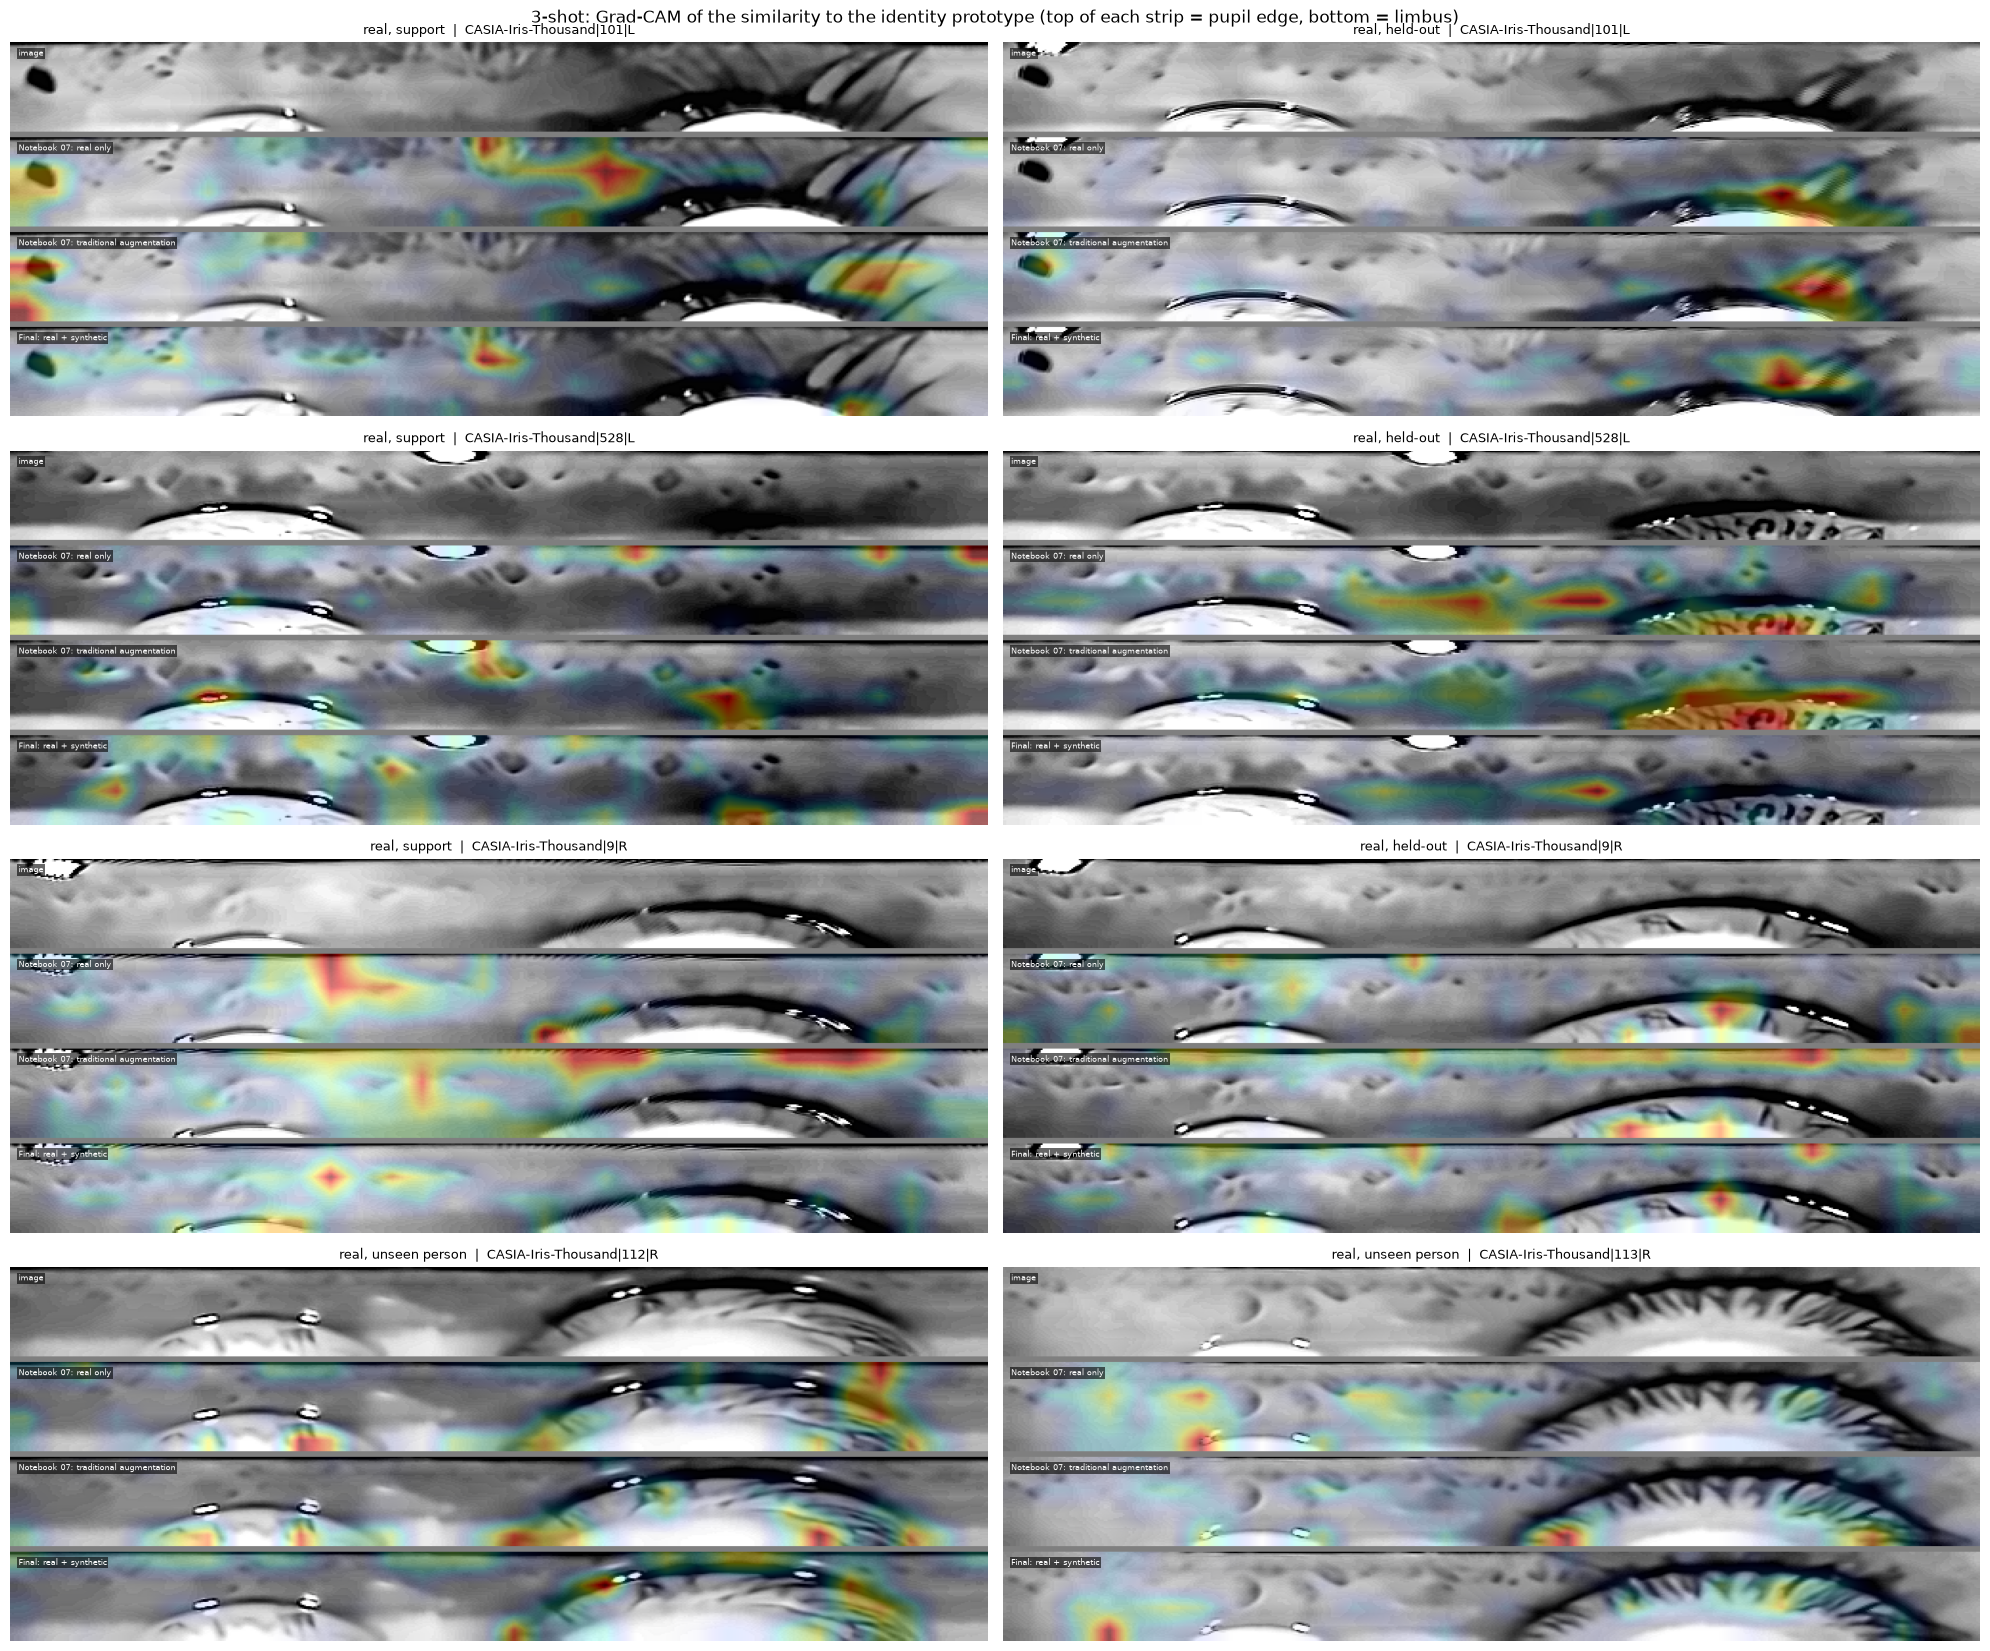

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\attention_maps_3shot.png


In [17]:
# ============================================================
# 14a. Attention maps
# ============================================================

ATTENTION_FIGURE_MAX = 8
METHOD_NAME = {"gradcam": "Grad-CAM", "rollout": "Attention Rollout"}[explanation_method(BACKBONE)]


def gray_rgb(image_uint8):
    gray = image_uint8.numpy().astype(np.float32) / 255.0
    return np.repeat(gray[..., None], 3, axis=2)


def overlay(image_uint8, attention, alpha=0.55):
    heat = attention.numpy().astype(np.float32)
    peak = float(heat.max())
    heat = heat / peak if peak > 0 else heat
    colored = plt.cm.jet(heat)[..., :3].astype(np.float32)
    weight = (alpha * heat)[..., None]
    return (1.0 - weight) * gray_rgb(image_uint8) + weight * colored


for shot in sorted({s for s, _ in explanations}):
    sets = sets_by_shot[shot]
    models_here = [spec for spec in MODEL_SPECS if (shot, spec["key"]) in explanations]
    positions = pick_evenly(list(range(len(sets["figure_indices"]))), ATTENTION_FIGURE_MAX)

    if not positions:
        print(f"{shot}-shot: no images for the attention figure.")
        continue

    composites = []
    for j in positions:
        image = sets["images"][sets["figure_indices"][j]]
        strips = [("image", gray_rgb(image))]
        for spec in models_here:
            strips.append((spec["name"], overlay(image, explanations[(shot, spec["key"])]["figure_maps"][j])))
        composites.append((sets["figure_titles"][j], strips))

    n_rows = math.ceil(len(composites) / 2)
    n_strips = 1 + len(models_here)
    fig, axes = plt.subplots(n_rows, 2, figsize=(20, n_rows * (0.9 * n_strips + 0.6)), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")

    for ax, (title, strips) in zip(axes.flatten(), composites):
        gap = 4
        parts, y = [], 0
        label_positions = []
        for i, (label, strip) in enumerate(strips):
            parts.append(strip)
            label_positions.append((y, label))
            y += strip.shape[0]
            if i < len(strips) - 1:
                parts.append(np.full((gap, strip.shape[1], 3), 0.5, dtype=np.float32))
                y += gap

        ax.imshow(np.vstack(parts), aspect="auto")
        for y0, label in label_positions:
            ax.text(4, y0 + 9, label, color="white", fontsize=6, bbox=dict(facecolor="black", alpha=0.6, pad=1, edgecolor="none"))
        ax.set_title(title, fontsize=9)

    plt.suptitle(f"{shot}-shot: {METHOD_NAME} of the similarity to the identity prototype "
                 f"(top of each strip = pupil edge, bottom = limbus)", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"attention_maps_{shot}shot.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

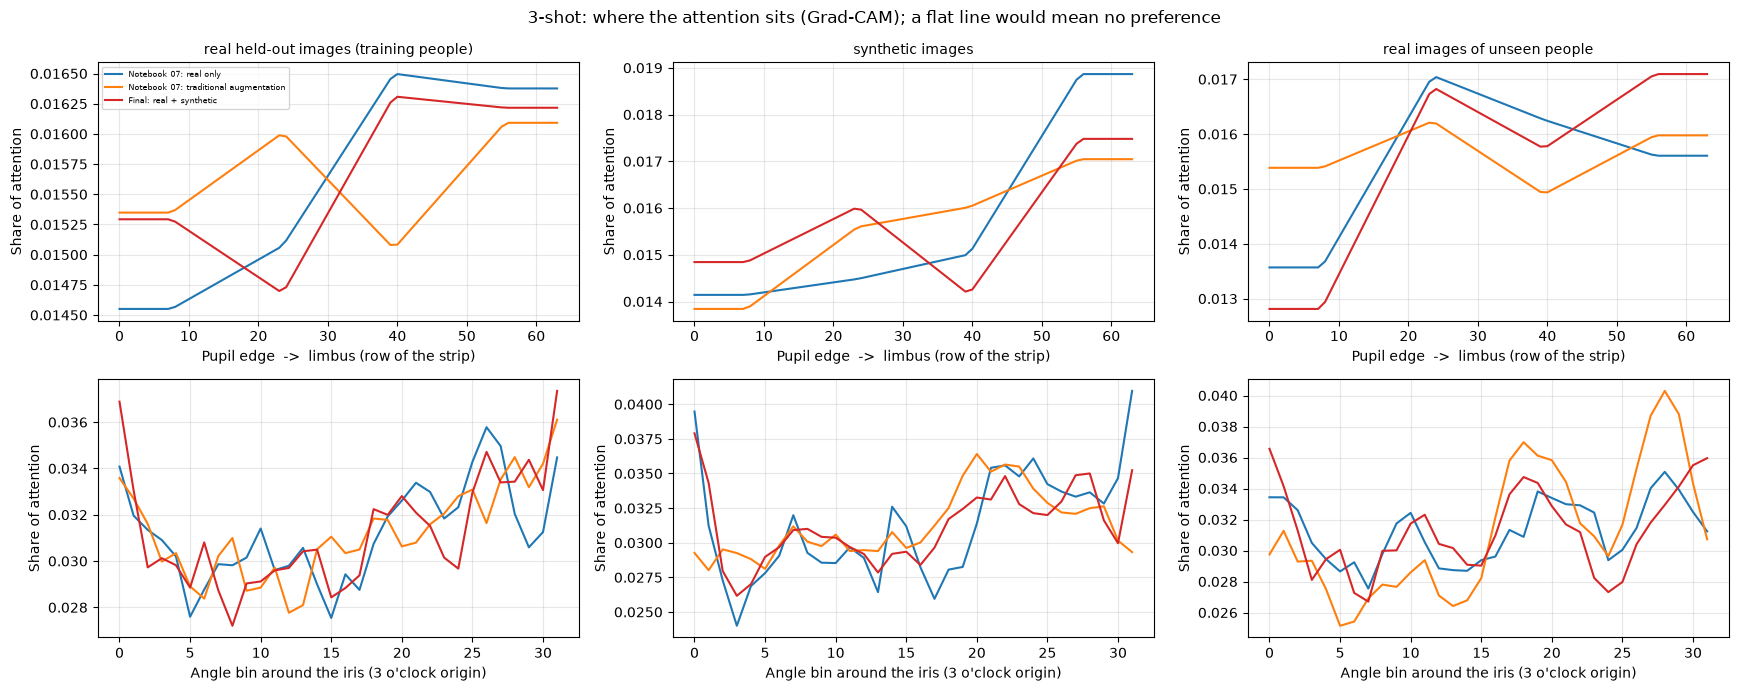

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\attention_profiles_3shot.png


In [18]:
# ============================================================
# 14b. Attention profiles
# ============================================================

GROUP_TITLES = {"real_heldout": "real held-out images (training people)", "synthetic": "synthetic images",
                "unseen_real": "real images of unseen people"}
model_colors = {spec["key"]: plt.cm.tab10(i % 10) for i, spec in enumerate(MODEL_SPECS)}

for shot in sorted({s for s, _ in explanations}):
    models_here = [spec for spec in MODEL_SPECS if (shot, spec["key"]) in explanations]
    groups_here = [g for g, _ in ATTENTION_GROUPS if any(g in explanations[(shot, s["key"])]["profiles"] for s in models_here)]

    fig, axes = plt.subplots(2, len(groups_here), figsize=(5.8 * len(groups_here), 7), squeeze=False)

    for column, group in enumerate(groups_here):
        for spec in models_here:
            profile = explanations[(shot, spec["key"])]["profiles"].get(group)
            if profile is None:
                continue
            for row, (name, label) in enumerate([("radial", "Pupil edge  ->  limbus (row of the strip)"),
                                                 ("angular", "Angle bin around the iris (3 o'clock origin)")]):
                values = profile[name]
                if np.isfinite(values).any():
                    axes[row, column].plot(np.arange(len(values)), values, color=model_colors[spec["key"]], label=spec["name"])
                axes[row, column].set_xlabel(label)

        axes[0, column].set_title(GROUP_TITLES[group], fontsize=10)
        axes[0, column].set_ylabel("Share of attention")
        axes[1, column].set_ylabel("Share of attention")
        for row in range(2):
            axes[row, column].grid(alpha=0.3)

    axes[0, 0].legend(fontsize=6)
    plt.suptitle(f"{shot}-shot: where the attention sits ({METHOD_NAME}); a flat line would mean no preference", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"attention_profiles_{shot}shot.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

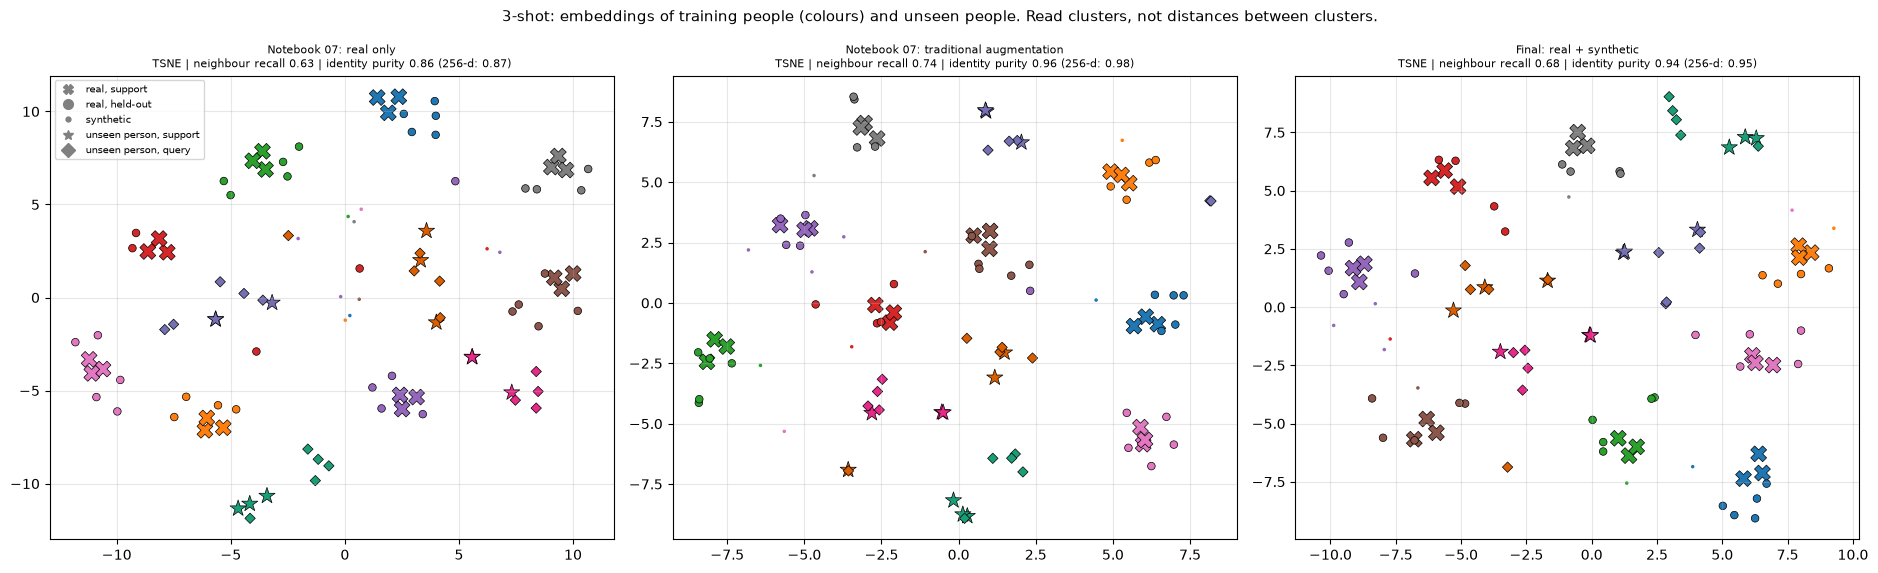

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\embedding_clusters_tsne_3shot.png


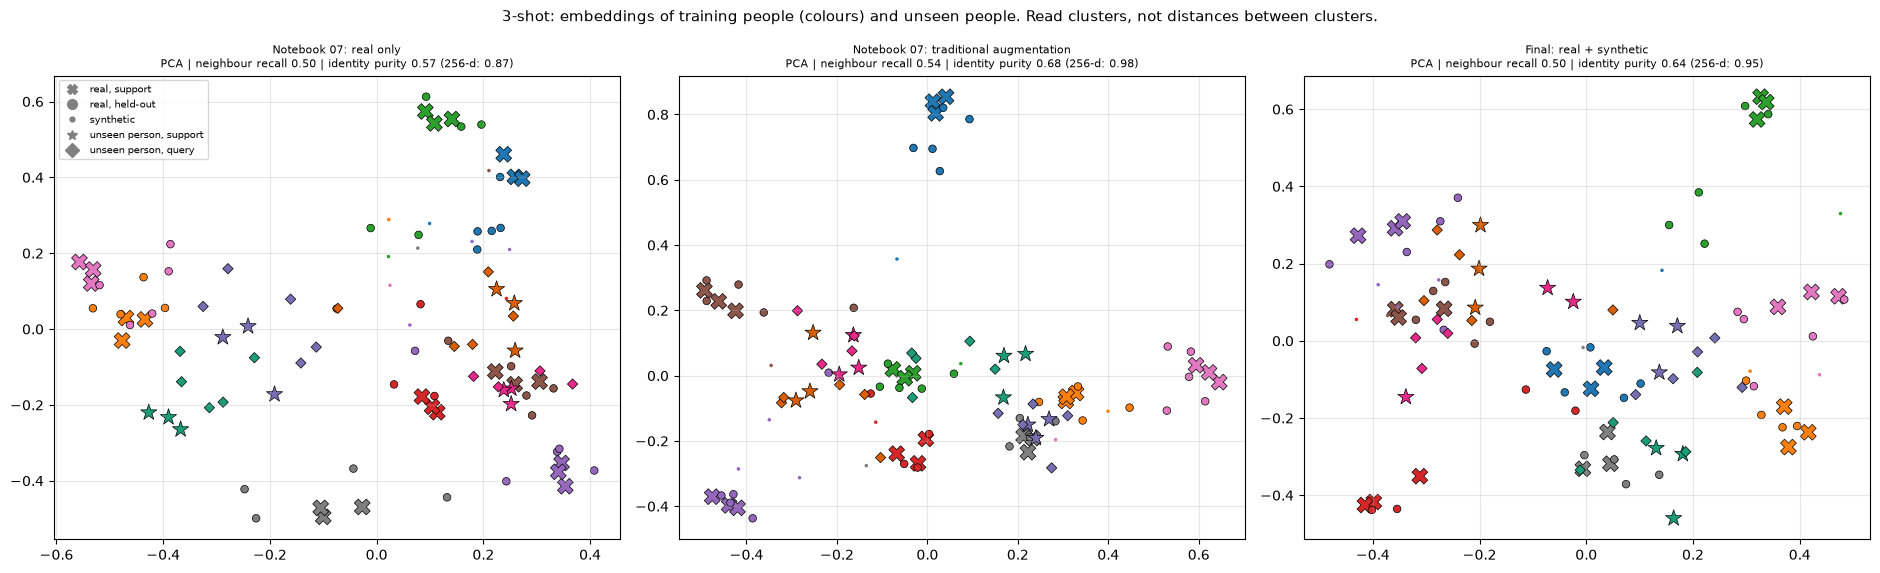

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\embedding_clusters_pca_3shot.png


In [19]:
# ============================================================
# 14c. Cluster pictures (t-SNE, UMAP or PCA)
# ============================================================

from matplotlib.lines import Line2D

KIND_STYLE = {"support": ("X", 130, "real, support"), "query": ("o", 30, "real, held-out"),
              "synthetic": (".", 26, "synthetic"), "unseen_support": ("*", 150, "unseen person, support"),
              "unseen_query": ("D", 28, "unseen person, query")}

for shot in sorted({s for s, _ in explanations}):
    sets, meta = sets_by_shot[shot], sets_by_shot[shot]["meta"]
    selected = np.asarray(sets["projection_indices"])
    kinds_p, classes_p = meta["kind"].to_numpy()[selected], meta["class_id"].to_numpy()[selected]

    unseen_classes = sorted(set(classes_p[np.isin(kinds_p, ["unseen_support", "unseen_query"])]))
    colors = {c: plt.cm.tab10(i % 10) for i, c in enumerate(sets["projection_classes"])}
    colors.update({c: plt.cm.Dark2(i % 8) for i, c in enumerate(unseen_classes)})

    methods_here = list(dict.fromkeys(m for (s, _), e in explanations.items() if s == shot for m in e["projections"]))

    for method in methods_here:
        models_here = [spec for spec in MODEL_SPECS if (shot, spec["key"]) in explanations
                       and method in explanations[(shot, spec["key"])]["projections"]]
        fig, axes = plt.subplots(1, len(models_here), figsize=(6.3 * len(models_here), 5.8), squeeze=False)

        for ax, spec in zip(axes[0], models_here):
            projection = explanations[(shot, spec["key"])]["projections"][method]
            coordinates = projection["coords"]

            for kind, (marker, size, _) in KIND_STYLE.items():
                mask = kinds_p == kind
                if bool(mask.any()):
                    ax.scatter(coordinates[mask, 0], coordinates[mask, 1], marker=marker, s=size,
                               c=[colors[c] for c in classes_p[mask]],
                               edgecolors="none" if kind == "synthetic" else "black", linewidths=0.5)

            used = projection["method_used"]
            ax.set_title(f"{spec['name']}\n{used.upper()}"
                         + (f" (requested {method})" if used != method else "")
                         + f" | neighbour recall {projection['neighbor_recall']:.2f} | "
                           f"identity purity {projection['label_1nn_2d']:.2f} (256-d: {projection['label_1nn_high']:.2f})",
                         fontsize=8)
            ax.grid(alpha=0.3)

        handles = [Line2D([0], [0], marker=marker, color="gray", linestyle="", markersize=7, label=label)
                   for kind, (marker, _, label) in KIND_STYLE.items() if bool((kinds_p == kind).any())]
        axes[0, 0].legend(handles=handles, fontsize=7, loc="best")
        plt.suptitle(f"{shot}-shot: embeddings of training people (colours) and unseen people. "
                     f"Read clusters, not distances between clusters.", fontsize=11)
        plt.tight_layout()
        path = RESULTS_DIR / f"embedding_clusters_{method}_{shot}shot.png"
        plt.savefig(path, dpi=150, bbox_inches="tight")
        plt.show()
        print("Saved:", path)

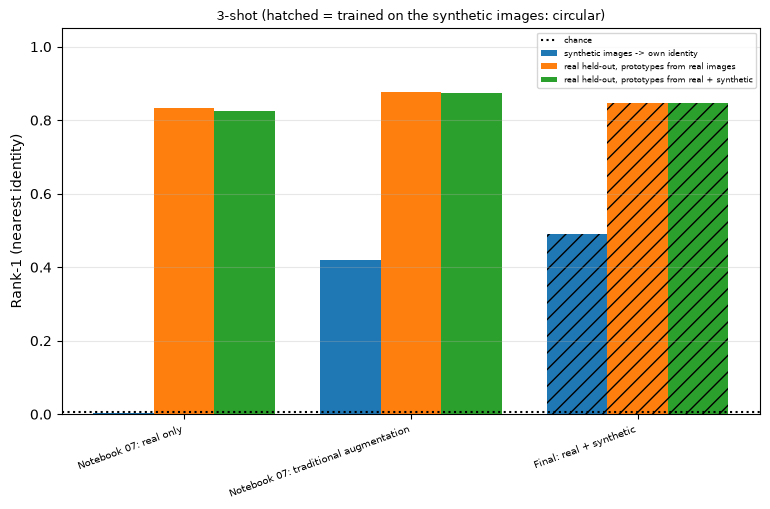

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability\identity_preservation.png


In [20]:
# ============================================================
# 14d. Identity-preservation bars
# ============================================================

bar_metrics = [("syn_rank1_own", "synthetic images -> own identity"),
               ("real_query_rank1_proto_real", "real held-out, prototypes from real images"),
               ("real_query_rank1_proto_real_syn", "real held-out, prototypes from real + synthetic")]

shots_here = sorted(preservation_table["shot"].unique())
fig, axes = plt.subplots(1, len(shots_here), figsize=(7.8 * len(shots_here), 5.2), squeeze=False)

for ax, shot in zip(axes[0], shots_here):
    rows = preservation_table[preservation_table["shot"] == shot].reset_index(drop=True)
    width = 0.8 / len(bar_metrics)

    for m, (column, label) in enumerate(bar_metrics):
        bars = ax.bar(np.arange(len(rows)) + m * width, rows[column], width, label=label)
        for bar, trained in zip(bars, rows["trained_on_synthetic"]):
            if trained:
                bar.set_hatch("//")

    ax.axhline(float(rows["chance_rank1"].iloc[0]), color="black", linestyle=":", label="chance")
    ax.set_xticks(np.arange(len(rows)) + width * (len(bar_metrics) - 1) / 2)
    ax.set_xticklabels(rows["model"], rotation=20, ha="right", fontsize=7)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Rank-1 (nearest identity)")
    ax.set_title(f"{shot}-shot (hatched = trained on the synthetic images: circular)", fontsize=9)
    ax.grid(axis="y", alpha=0.3)

axes[0, 0].legend(fontsize=6)
plt.tight_layout()
path = RESULTS_DIR / "identity_preservation.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 15. Sanity checks

**Stop the notebook if:**
- a model with a checkpoint was not explained, or a shot has no explained model;
- the analysis sets lack real support, real held-out, or synthetic images;
- an attention map is not finite and non-negative, or an attention profile does not sum to 1;
- an identity-preservation rate is outside `[0, 1]`, or a projection has non-finite coordinates;
- a results file was not written.

**Warn if** (these describe expected behaviour, not guaranteed behaviour). Models trained on the synthetic images are **left out of the identity checks** (they are circular):
- no model that never saw the synthetic images is available as an independent judge;
- an independent judge finds the synthetic images' own identity at no more than twice chance;
- the synthetic images are far less varied (ratio below 0.5) or far more varied (above 2) than the real ones in embedding space;
- adding the synthetic images to the prototypes lowers the real held-out Rank-1 by more than 0.05;
- more than 5% of the attention maps are empty;
- the valid-texture ratio on real held-out images is below 0.8 (the model looks mostly at eyelid, eyelash, or reflection areas);
- a projection hides label structure (2-D identity purity more than 0.15 below the 256-d value).

In [23]:
# ============================================================
# 15. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected = {(shot, spec["key"]) for shot in shots_to_run for spec in MODEL_SPECS if model_path(spec, shot).exists()}
add_check("every model with a checkpoint was explained", set(explanations) == expected, f"{len(expected - set(explanations))} missing")
add_check("every shot has at least one explained model", all(any(s == shot for s, _ in explanations) for shot in shots_to_run))

for shot, sets in sets_by_shot.items():
    present = set(sets["meta"]["kind"])
    add_check(f"{shot}-shot: the analysis sets contain real support, real held-out, and synthetic images",
              {"support", "query", "synthetic"} <= present, f"found {sorted(present)}")

maps_ok = all(len(e["figure_maps"]) == 0 or (bool(torch.isfinite(e["figure_maps"]).all()) and float(e["figure_maps"].min()) >= 0.0)
              for e in explanations.values())
add_check("all attention maps are finite and non-negative", maps_ok)

profiles_ok = True
for e in explanations.values():
    for profile in e["profiles"].values():
        for values in (profile["radial"], profile["angular"]):
            if np.isfinite(values).all() and abs(float(values.sum()) - 1.0) > 1e-4:
                profiles_ok = False
add_check("every attention profile sums to 1", profiles_ok)

rate_columns = ["syn_rank1_own", "real_query_rank1_proto_real", "real_query_rank1_proto_real_syn",
                "real_query_1nn_real", "real_query_1nn_real_syn"]
rates = preservation_table[rate_columns].to_numpy()
add_check("identity-preservation rates lie in [0, 1]", bool(((rates >= 0) & (rates <= 1)).all()))

add_check("all projection coordinates are finite",
          all(bool(np.isfinite(p["coords"]).all()) for e in explanations.values() for p in e["projections"].values()))

written = [name for name in ["identity_preservation", "attention_statistics", "attention_profiles", "projection_quality",
                             "projection_coordinates", "explainability_models"] if not (RESULTS_DIR / f"{name}.csv").exists()]
add_check("every results table was written", not written, f"missing: {written}")

# ---- warnings ----
independent = preservation_table[~preservation_table["trained_on_synthetic"]]
add_check("an independent judge (a model that never saw the synthetic images) is available", len(independent) > 0,
          "all explained models were trained on the synthetic images, so the identity numbers are circular", critical=False)

for _, row in independent.iterrows():
    label = f"{int(row['shot'])}-shot / {row['model']}"
    add_check(f"{label}: synthetic images are nearest to their own identity at more than twice chance",
              row["syn_rank1_own"] > 2 * row["chance_rank1"], f"{row['syn_rank1_own']:.3f} vs chance {row['chance_rank1']:.3f}", critical=False)
    if np.isfinite(row["diversity_ratio_embedding"]):
        add_check(f"{label}: variation of the synthetic images is between 0.5 and 2 times the real variation",
                  0.5 <= row["diversity_ratio_embedding"] <= 2.0, f"ratio {row['diversity_ratio_embedding']:.2f}", critical=False)
    add_check(f"{label}: adding synthetic images to the prototypes does not lower the real held-out Rank-1 by more than 0.05",
              row["real_query_rank1_proto_real_syn"] >= row["real_query_rank1_proto_real"] - 0.05,
              f"{row['real_query_rank1_proto_real']:.3f} -> {row['real_query_rank1_proto_real_syn']:.3f}", critical=False)

empty = attention_table[attention_table["empty_fraction"] > 0.05]
add_check("fewer than 5% of the attention maps are empty", len(empty) == 0, f"{len(empty)} group(s) with more", critical=False)

valid_rows = attention_table[(attention_table["group"] == "real_heldout") & np.isfinite(attention_table["valid_ratio"])]
low_valid = valid_rows[valid_rows["valid_ratio"] < 0.8]
add_check("the attention on real held-out images favours valid iris texture (ratio of at least 0.8)", len(low_valid) == 0,
          f"{len(low_valid)} of {len(valid_rows)} model(s) below 0.8", critical=False)

hidden = quality_table[quality_table["label_1nn_2d"] < quality_table["label_1nn_high"] - 0.15]
add_check("the projections keep the identity structure of the embeddings", len(hidden) == 0,
          f"{len(hidden)} of {len(quality_table)} picture(s) lose more than 0.15", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "explainability_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "explainability_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical explainability checks failed: {failed_names}"
print("\nExplainability sanity checks completed with no critical failures.")

[PASS] every model with a checkpoint was explained  (0 missing)
[PASS] every shot has at least one explained model
[PASS] 3-shot: the analysis sets contain real support, real held-out, and synthetic images  (found ['query', 'support', 'synthetic', 'unseen_query', 'unseen_support'])
[PASS] all attention maps are finite and non-negative
[PASS] every attention profile sums to 1
[PASS] identity-preservation rates lie in [0, 1]
[PASS] all projection coordinates are finite
[PASS] every results table was written  (missing: [])
[PASS] an independent judge (a model that never saw the synthetic images) is available  (all explained models were trained on the synthetic images, so the identity numbers are circular)
[WARN] 3-shot / Notebook 07: real only: synthetic images are nearest to their own identity at more than twice chance  (0.003 vs chance 0.005)
[PASS] 3-shot / Notebook 07: real only: variation of the synthetic images is between 0.5 and 2 times the real variation  (ratio 1.31)
[PASS] 3-sho

## 16. Final outputs

At the end of Notebook 15, the project should contain:

```text
results/explainability/
├── identity_preservation.csv, identity_preservation.png     identity numbers and bars (circular rows are marked)
├── attention_statistics.csv, attention_profiles.csv         attention numbers behind the figures
├── projection_quality.csv, projection_coordinates.csv       quality and coordinates of the cluster pictures
├── explainability_models.csv, explainability_sanity_checks.csv
├── attention_maps_<K>shot.png                               Grad-CAM / Attention Rollout overlays
├── attention_profiles_<K>shot.png                           where along and around the iris the attention sits
└── embedding_clusters_<method>_<K>shot.png                  t-SNE / UMAP (or PCA) cluster pictures
```

In [24]:
# ============================================================
# 16. Final output listing
# ============================================================

print("Notebook 15 output directory:")
print(RESULTS_DIR)

print("\nGenerated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nModels explained: {len(explanations)} | shots: {sorted({s for s, _ in explanations})} | "
      f"attention method: {METHOD_NAME} | projections: {list(dict.fromkeys(active_methods))}")
print("\nNotebook 15 completed.")

Notebook 15 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\explainability

Generated files:
- attention_maps_3shot.png
- attention_profiles.csv
- attention_profiles_3shot.png
- attention_statistics.csv
- embedding_clusters_pca_3shot.png
- embedding_clusters_tsne_3shot.png
- explainability_models.csv
- explainability_sanity_checks.csv
- identity_preservation.csv
- identity_preservation.png
- projection_coordinates.csv
- projection_quality.csv

Models explained: 3 | shots: [3] | attention method: Grad-CAM | projections: ['tsne', 'pca']

Notebook 15 completed.


## 17. What this notebook hands to the rest of the project

```text
Notebooks 07, 13, 14                 Notebook 15                           Notebooks 16 - 18
Trained recognizers,       --->      Explanations:                  --->   16: ablations (what changes when settings change)
cross-dataset results                attention, clusters,                  17: figures and tables for the paper
                                     identity preservation                 18: significance tests
```

### How the outputs are used

| Notebook | Use |
|---|---|
| **16 Ablations** | Re-run this notebook after each ablation to see whether attention or identity preservation changes with the setting (guidance scale, number of synthetic images, filter threshold, loss) |
| **17 Performance comparison** | The identity-preservation table and the cluster and attention figures are the qualitative part of the comparison. State the attention method (`METHOD_NAME`), the projection method actually used, and which rows are circular |
| **18 Statistical significance** | `identity_preservation.csv` is per model and shot. For confidence intervals resample **identities**, not images, and use several seeds |

### Rules for reporting

1. **Attention maps are descriptive, not causal.** Say "the model attends to X", not "the model is accurate because of X".
2. **t-SNE and UMAP distort distances.** Report `neighbor_recall` and the identity purity with every picture, and say which method was actually used (UMAP can fall back to PCA).
3. **The valid-texture ratio is a proxy.** No crypt or furrow annotations exist for these datasets, and the proposal's structural consistency score and expert ratings are not implemented. Do not call the ratio a crypt overlap.
4. **Identity numbers of a model that was trained on the synthetic images are circular.** Report the independent judges (the Notebook 07 baselines and the same-code control) for the synthetic images.
5. State `SYNTHETIC_SOURCE`, the shot, the seed, and the number of identities and images analysed.

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| Attention piles up at the limbus or the eyelid side | The model uses boundary or occlusion cues | Check the valid-texture ratio; look at Notebook 04 enhancement and Notebook 05 quality filtering |
| Flat attention profiles, high entropy | Attention is spread over the whole strip, or the layer is too coarse | Compare models; try another `GRADCAM_LAYERS` entry |
| Synthetic images sit apart from their person's real images in the clusters | The generator drifts away from the real texture | Check Notebooks 09 to 12 (generator training, acceptance, diversity) |
| Synthetic images collapse onto the real support images | Copying, low variation | `diversity_ratio_embedding` well below 1; see Notebook 12's novelty ratio |
| `syn_rank1_own` far below the real held-out Rank-1 | The synthetic images carry less identity than real ones | Raise the acceptance threshold in Notebook 11 or improve the generator |
| Adding synthetic images lowers the real held-out Rank-1 | They pull the prototypes away from the real ones | Use fewer synthetic images per identity, or only the accepted ones |
| The picture looks like noise but `neighbor_recall` is high | Clusters are real but the colours are hard to read | Show fewer identities (`PROJECTION_IDENTITIES`) |